In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_u_2D, plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together
from PwpHex_class import PiecewiseLinearPolynomialsHex
from minmax_opt_class_mgnn_2d import MinMaxOptProb2D
from minmax_opt_class_mgnn import MinMaxOptProb

C:\Users\hao6li\Projects\NN-HCL\Code\minmax_opt_class_mgnn_2d.py:49: SyntaxWarning: "is" with a literal. Did you mean "=="?
  if self.dg_type is 'P1':
C:\Users\hao6li\Projects\NN-HCL\Code\minmax_opt_class_mgnn_2d.py:51: SyntaxWarning: "is" with a literal. Did you mean "=="?
  elif self.dg_type is 'Q1':


In [2]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1

import numpy as np

def u_ref(t, x, y):
    """
    Exact solution u(t, x, y) for the 2D Burgers equation.
    """
    cond1 = x <= 0.5 - 3*t/5
    cond2 = (0.5 - 3*t/5 < x) & (x <= 0.5 - t/4)
    cond3 = (0.5 - t/4 < x) & (x <= 0.5 + t/2)
    cond4 = (0.5 + t/2 < x) & (x <= 0.5 + 4*t/5)
    cond5 = x > 0.5 + 4*t/5
    u = np.zeros_like(x)

    # Case 1
    cond1 = cond1
    u[cond1] = np.where(y[cond1] > 0.5 + 3*t[cond1]/20, -0.2, 0.5)

    # Case 2
    u[cond2] = np.where(y[cond2] > -8*x[cond2]/7 + 15/14 - 15*t[cond2]/28, -1, 0.5)

    # Case 3
    u[cond3] = np.where(y[cond3] > x[cond3]/6 + 5/12 - 5*t[cond3]/24, -1, 0.5)

    # Case 4
    u[cond4] = np.where(y[cond4] > x[cond4] - (5/(18*t[cond4])) * (x[cond4] + t[cond4] - 0.5)**2, -1, (2*x[cond4] - 1)/(2*t[cond4]))

    # Case 5
    u[cond5] = np.where(y[cond5] > 0.5 - t[cond5]/10, -1, 0.8)
    return u

def u0(x, y):
    """
    Initial condition u0(x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min.
    """
    return u_ref(t, x_min*np.zeros_like(t), y)

def u_right(t, y):
    """
    Boundary condition at x = x_max.
    """
    return u_ref(t, x_max*np.ones_like(t), y)

def u_bottom(t, x):
    """
    Boundary condition at y = y_min.
    """
    return u_ref(t, x, y_min*np.zeros_like(t))

def u_top(t, x):
    """
    Boundary condition at y = y_max.
    """
    return u_ref(t, x, y_max*np.ones_like(t))

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

N_t = 20
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(
    input_dim=3, num_segments=3, 
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.1667]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
The largest W^{1,inf} norm of k_h coeffs is 7.585487
Grade 0, Iter 0, lambda_ic: 18.723894, lambda_bc: 18.327168, lambda_eqn: 1.079790
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
Grade 0, Iter 0, loss_eqn: 0.410826, loss_eqn_from_kh: 0.410656, loss_l1: 0.410656, loss_ibc: 2.542315


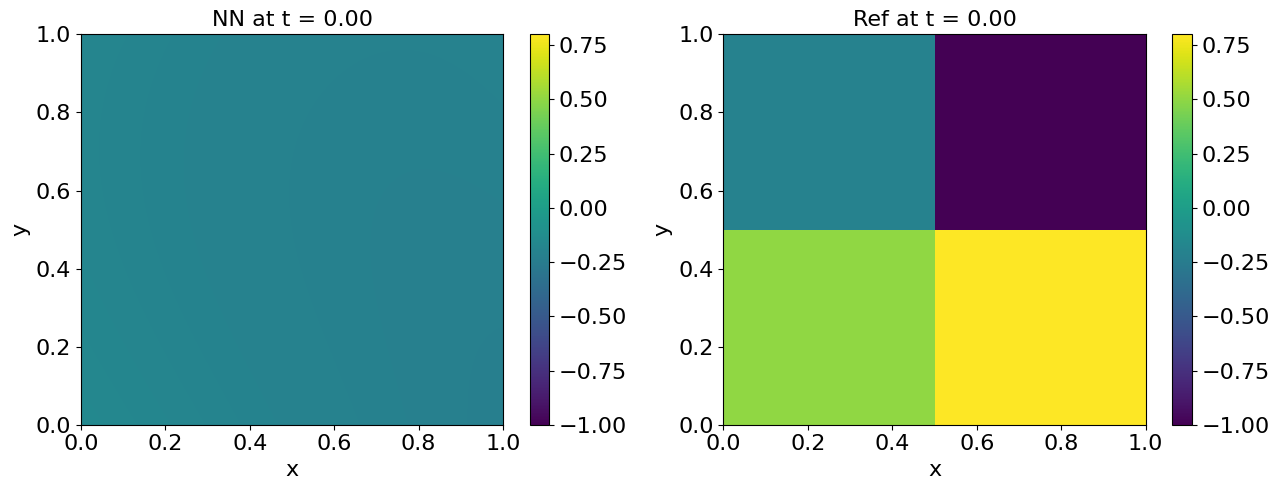

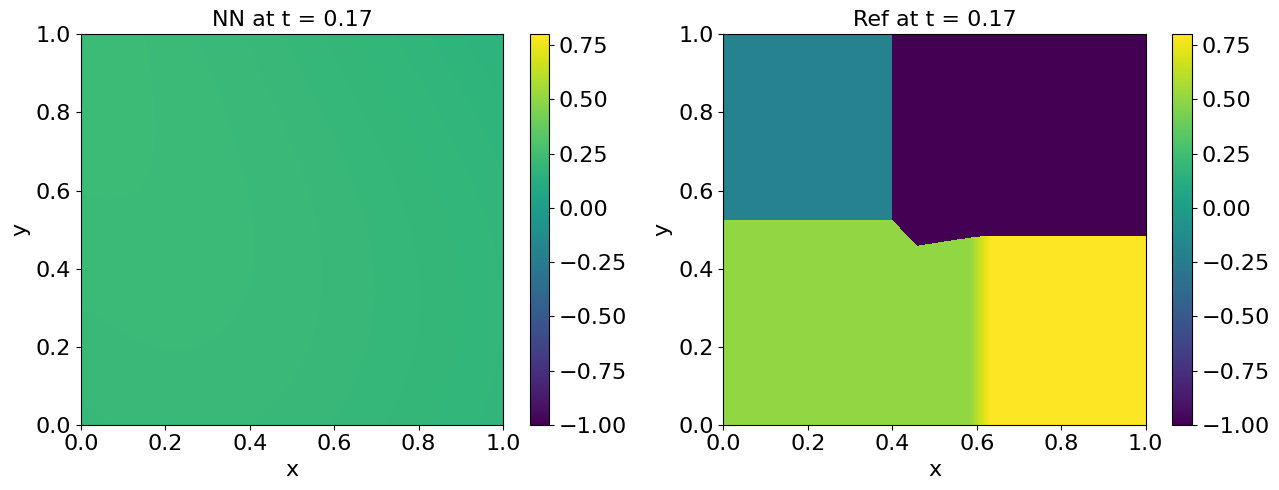

Grade 0, Iter 100, loss_eqn: 0.104723, loss_eqn_from_kh: 0.107090, loss_l1: 0.107094, loss_ibc: 0.512039
Grade 0, Iter 200, loss_eqn: 0.138961, loss_eqn_from_kh: 0.138974, loss_l1: 0.160278, loss_ibc: 0.124331
Grade 0, Iter 300, loss_eqn: 0.098110, loss_eqn_from_kh: 0.099841, loss_l1: 0.166645, loss_ibc: 0.054808
Grade 0, Iter 400, loss_eqn: 0.079484, loss_eqn_from_kh: 0.077727, loss_l1: 0.098014, loss_ibc: 0.030850
Grade 0, Iter 500, loss_eqn: 0.052393, loss_eqn_from_kh: 0.052138, loss_l1: 0.066443, loss_ibc: 0.017810
Grade 0, Iter 600, loss_eqn: 0.037991, loss_eqn_from_kh: 0.038264, loss_l1: 0.050913, loss_ibc: 0.012395
Grade 0, Iter 700, loss_eqn: 0.030412, loss_eqn_from_kh: 0.030448, loss_l1: 0.041980, loss_ibc: 0.008426
Grade 0, Iter 800, loss_eqn: 0.026463, loss_eqn_from_kh: 0.026318, loss_l1: 0.038633, loss_ibc: 0.006533
Grade 0, Iter 900, loss_eqn: 0.024331, loss_eqn_from_kh: 0.024439, loss_l1: 0.037098, loss_ibc: 0.005214
Grade 0, Iter 1000, loss_eqn: 0.022769, loss_eqn_from_k

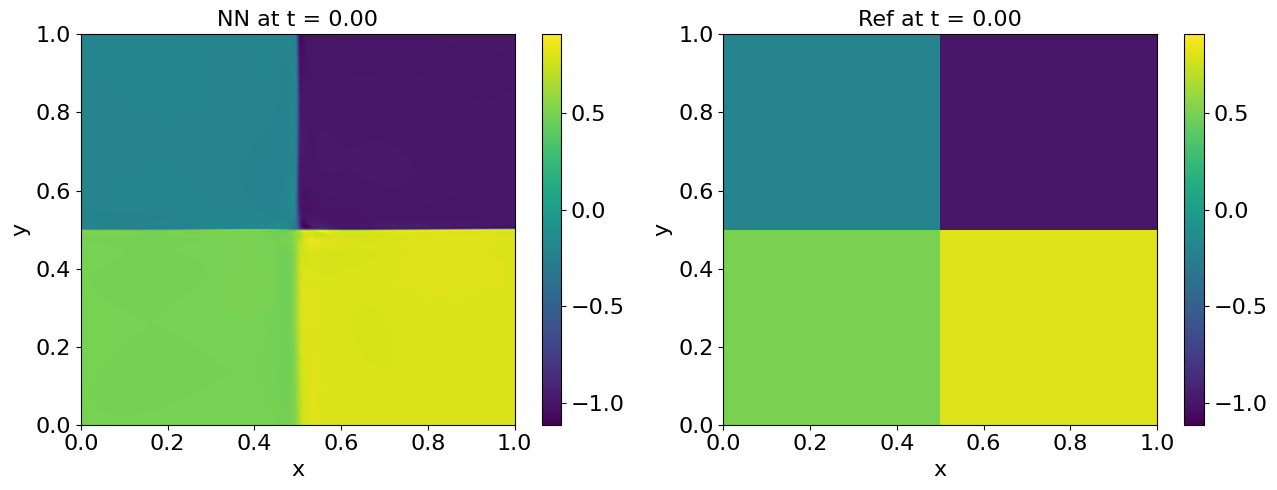

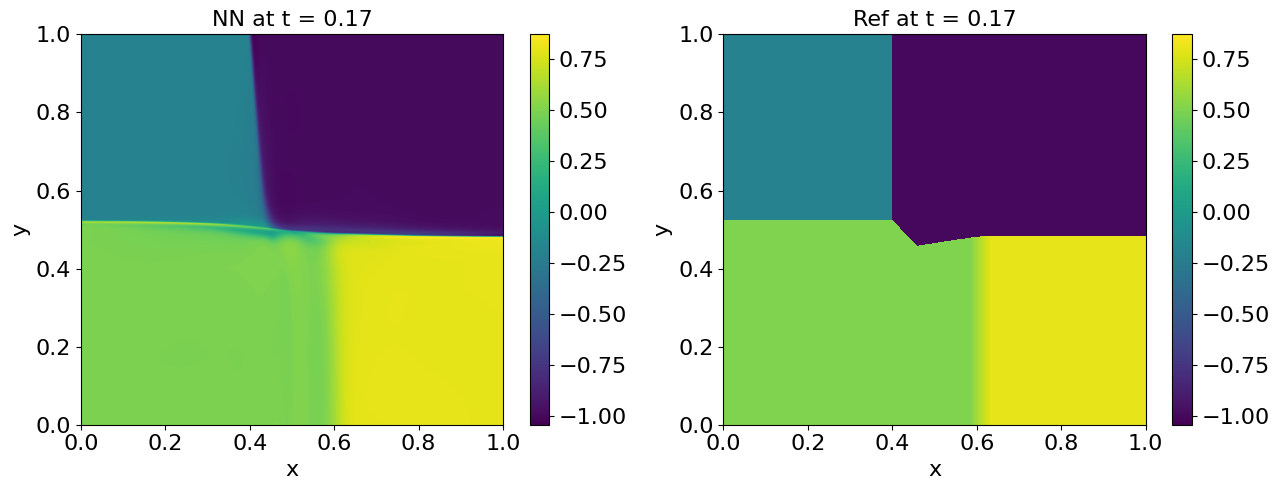

Grade 0, Iter 2100, loss_eqn: 0.013254, loss_eqn_from_kh: 0.012870, loss_l1: 0.029045, loss_ibc: 0.001625
Grade 0, Iter 2200, loss_eqn: 0.012433, loss_eqn_from_kh: 0.012144, loss_l1: 0.029006, loss_ibc: 0.001596
Grade 0, Iter 2300, loss_eqn: 0.011525, loss_eqn_from_kh: 0.011533, loss_l1: 0.029410, loss_ibc: 0.001492
Grade 0, Iter 2400, loss_eqn: 0.010992, loss_eqn_from_kh: 0.010891, loss_l1: 0.028601, loss_ibc: 0.001326
Grade 0, Iter 2500, loss_eqn: 0.009969, loss_eqn_from_kh: 0.010209, loss_l1: 0.027792, loss_ibc: 0.001244
Grade 0, Iter 2600, loss_eqn: 0.010250, loss_eqn_from_kh: 0.010073, loss_l1: 0.027859, loss_ibc: 0.001212
Grade 0, Iter 2700, loss_eqn: 0.009583, loss_eqn_from_kh: 0.009901, loss_l1: 0.027509, loss_ibc: 0.001357
Grade 0, Iter 2800, loss_eqn: 0.009156, loss_eqn_from_kh: 0.009176, loss_l1: 0.025869, loss_ibc: 0.001193
Grade 0, Iter 2900, loss_eqn: 0.008655, loss_eqn_from_kh: 0.008920, loss_l1: 0.024943, loss_ibc: 0.001161
Grade 0, Iter 3000, loss_eqn: 0.008897, loss_e

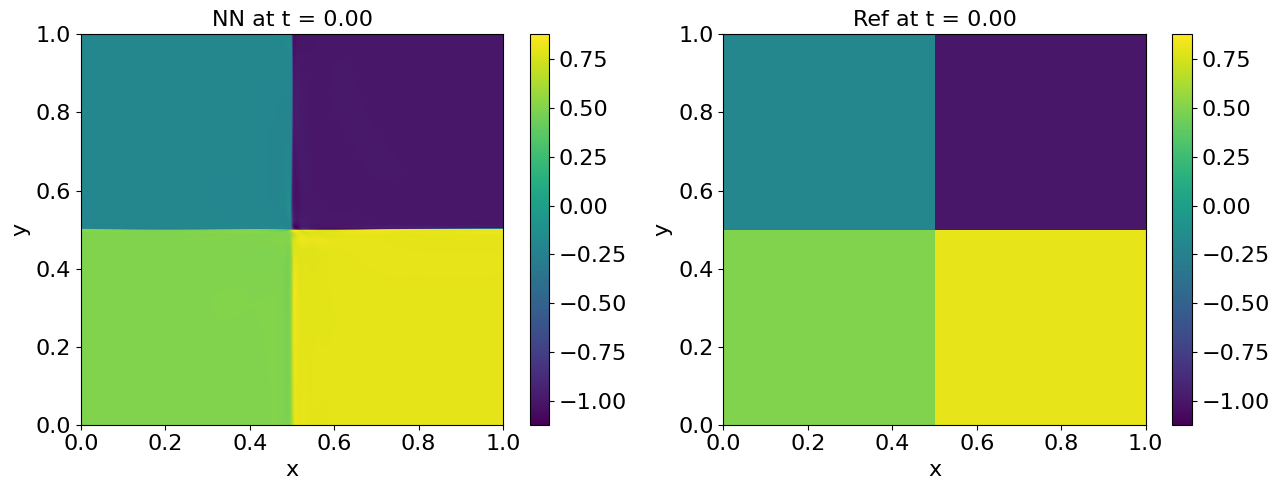

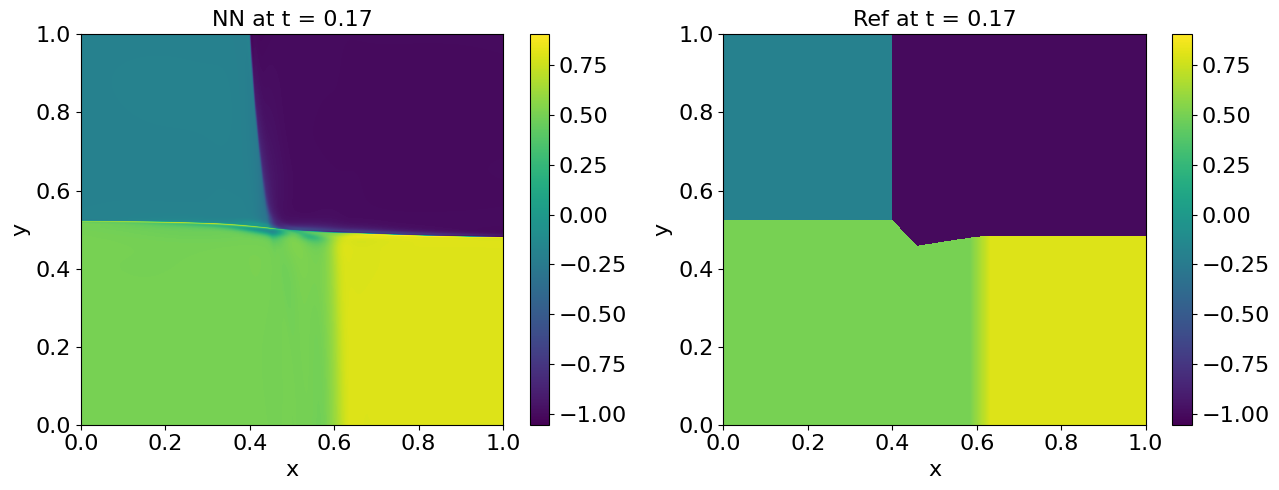

Grade 0, Iter 4100, loss_eqn: 0.005940, loss_eqn_from_kh: 0.006112, loss_l1: 0.019912, loss_ibc: 0.000679
Grade 0, Iter 4200, loss_eqn: 0.005771, loss_eqn_from_kh: 0.005563, loss_l1: 0.019776, loss_ibc: 0.000648
Grade 0, Iter 4300, loss_eqn: 0.007612, loss_eqn_from_kh: 0.006698, loss_l1: 0.020618, loss_ibc: 0.000705
Grade 0, Iter 4400, loss_eqn: 0.005895, loss_eqn_from_kh: 0.005503, loss_l1: 0.019345, loss_ibc: 0.000670
Grade 0, Iter 4500, loss_eqn: 0.005851, loss_eqn_from_kh: 0.005565, loss_l1: 0.019232, loss_ibc: 0.000553
Grade 0, Iter 4600, loss_eqn: 0.006372, loss_eqn_from_kh: 0.006191, loss_l1: 0.018955, loss_ibc: 0.000564
Grade 0, Iter 4700, loss_eqn: 0.006000, loss_eqn_from_kh: 0.005642, loss_l1: 0.018426, loss_ibc: 0.000612
Grade 0, Iter 4800, loss_eqn: 0.005337, loss_eqn_from_kh: 0.005396, loss_l1: 0.018398, loss_ibc: 0.000516
Grade 0, Iter 4900, loss_eqn: 0.005025, loss_eqn_from_kh: 0.005385, loss_l1: 0.018317, loss_ibc: 0.000526
Grade 0, Iter 5000, loss_eqn: 0.004853, loss_e

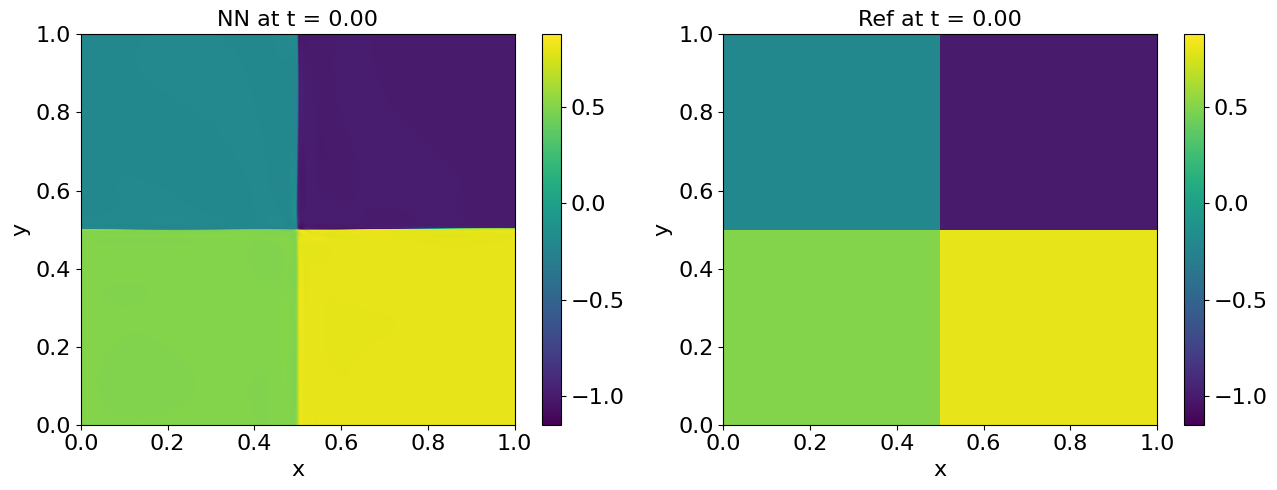

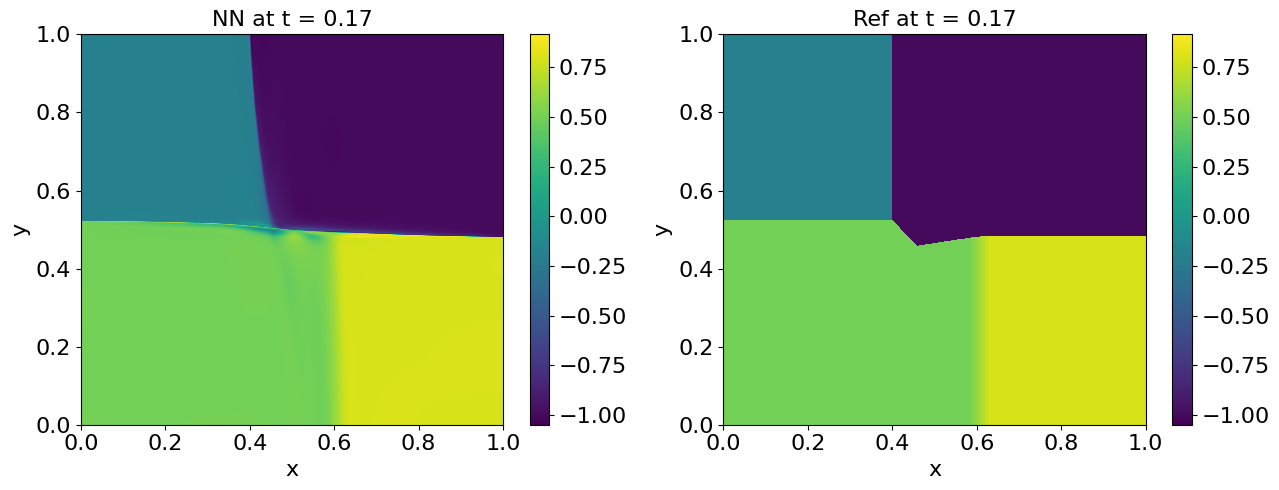

Grade 0, Iter 6100, loss_eqn: 0.004177, loss_eqn_from_kh: 0.004263, loss_l1: 0.016430, loss_ibc: 0.000405
Grade 0, Iter 6200, loss_eqn: 0.003896, loss_eqn_from_kh: 0.003979, loss_l1: 0.016328, loss_ibc: 0.000413
Grade 0, Iter 6300, loss_eqn: 0.004093, loss_eqn_from_kh: 0.003988, loss_l1: 0.016176, loss_ibc: 0.000382
Grade 0, Iter 6400, loss_eqn: 0.004719, loss_eqn_from_kh: 0.004013, loss_l1: 0.016458, loss_ibc: 0.000398
Grade 0, Iter 6500, loss_eqn: 0.003924, loss_eqn_from_kh: 0.004288, loss_l1: 0.016286, loss_ibc: 0.000375
Grade 0, Iter 6600, loss_eqn: 0.004135, loss_eqn_from_kh: 0.003833, loss_l1: 0.016263, loss_ibc: 0.000372
Grade 0, Iter 6700, loss_eqn: 0.004660, loss_eqn_from_kh: 0.003893, loss_l1: 0.015962, loss_ibc: 0.000376
Grade 0, Iter 6800, loss_eqn: 0.003979, loss_eqn_from_kh: 0.003957, loss_l1: 0.016094, loss_ibc: 0.000365
Grade 0, Iter 6900, loss_eqn: 0.004021, loss_eqn_from_kh: 0.003843, loss_l1: 0.015901, loss_ibc: 0.000372
Grade 0, Iter 7000, loss_eqn: 0.003861, loss_e

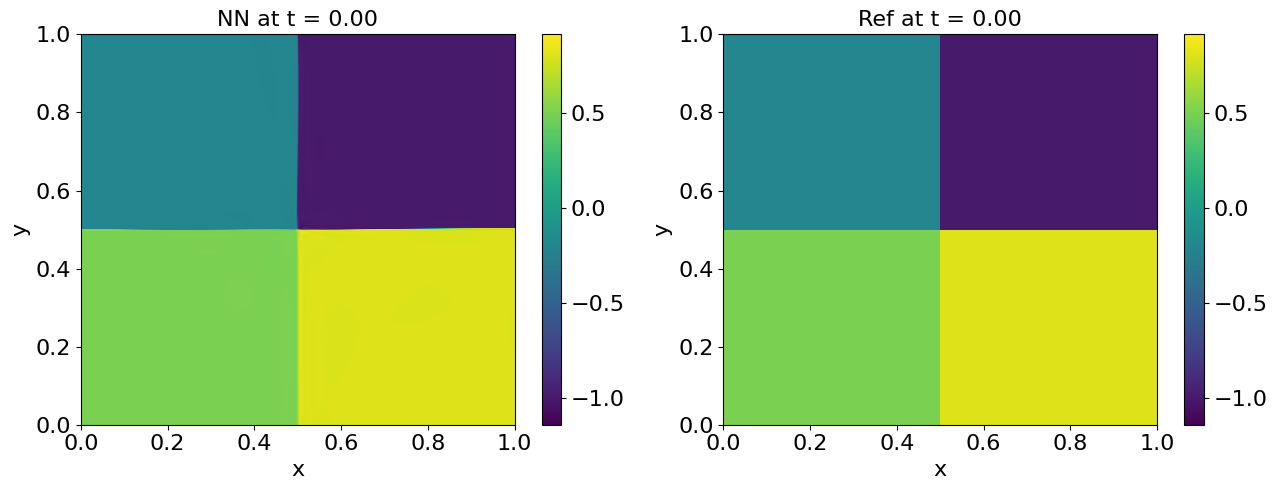

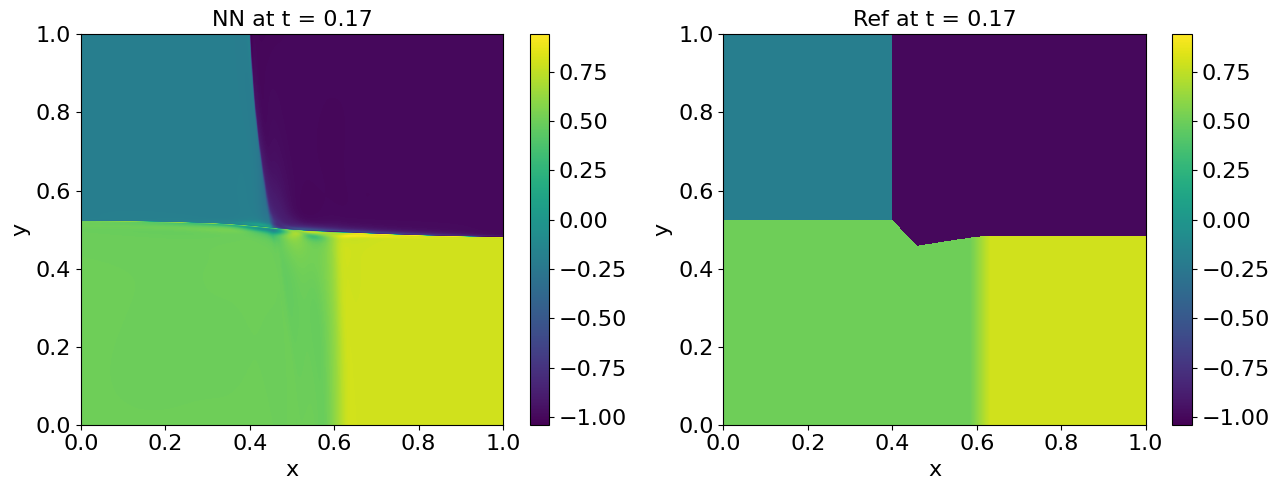

Grade 0, Iter 8100, loss_eqn: 0.003440, loss_eqn_from_kh: 0.003598, loss_l1: 0.015313, loss_ibc: 0.000321
Grade 0, Iter 8200, loss_eqn: 0.003435, loss_eqn_from_kh: 0.003440, loss_l1: 0.015272, loss_ibc: 0.000319
Grade 0, Iter 8300, loss_eqn: 0.003433, loss_eqn_from_kh: 0.003368, loss_l1: 0.015182, loss_ibc: 0.000318
Grade 0, Iter 8400, loss_eqn: 0.003340, loss_eqn_from_kh: 0.003404, loss_l1: 0.015175, loss_ibc: 0.000316
Grade 0, Iter 8500, loss_eqn: 0.003302, loss_eqn_from_kh: 0.003282, loss_l1: 0.015021, loss_ibc: 0.000317
Grade 0, Iter 8600, loss_eqn: 0.003767, loss_eqn_from_kh: 0.003500, loss_l1: 0.015218, loss_ibc: 0.000303
Grade 0, Iter 8700, loss_eqn: 0.003292, loss_eqn_from_kh: 0.003377, loss_l1: 0.015038, loss_ibc: 0.000311
Grade 0, Iter 8800, loss_eqn: 0.003238, loss_eqn_from_kh: 0.003254, loss_l1: 0.014964, loss_ibc: 0.000310
Grade 0, Iter 8900, loss_eqn: 0.003286, loss_eqn_from_kh: 0.003288, loss_l1: 0.014960, loss_ibc: 0.000306
Grade 0, Iter 9000, loss_eqn: 0.003258, loss_e

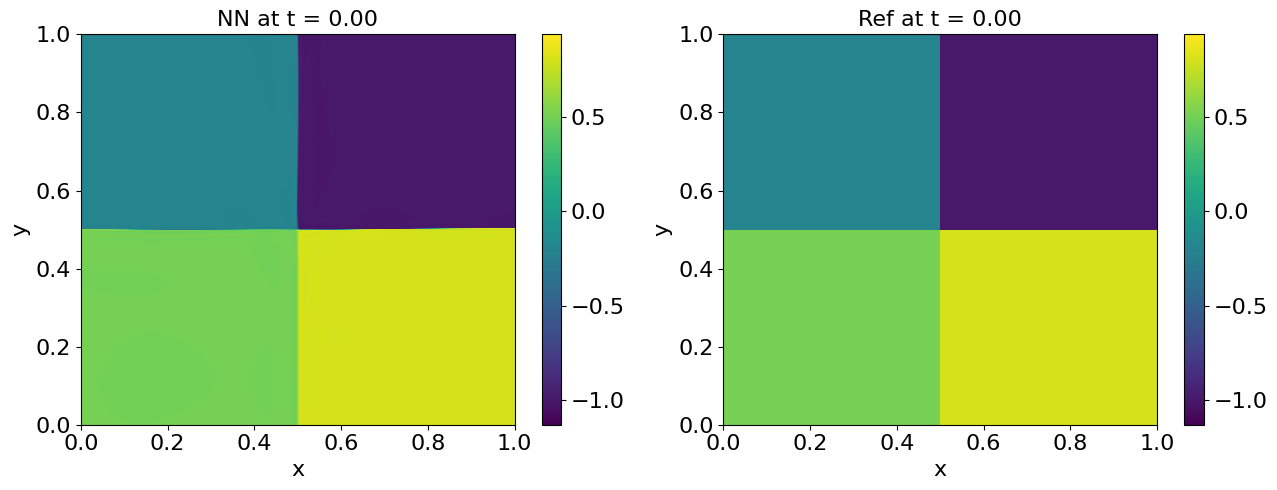

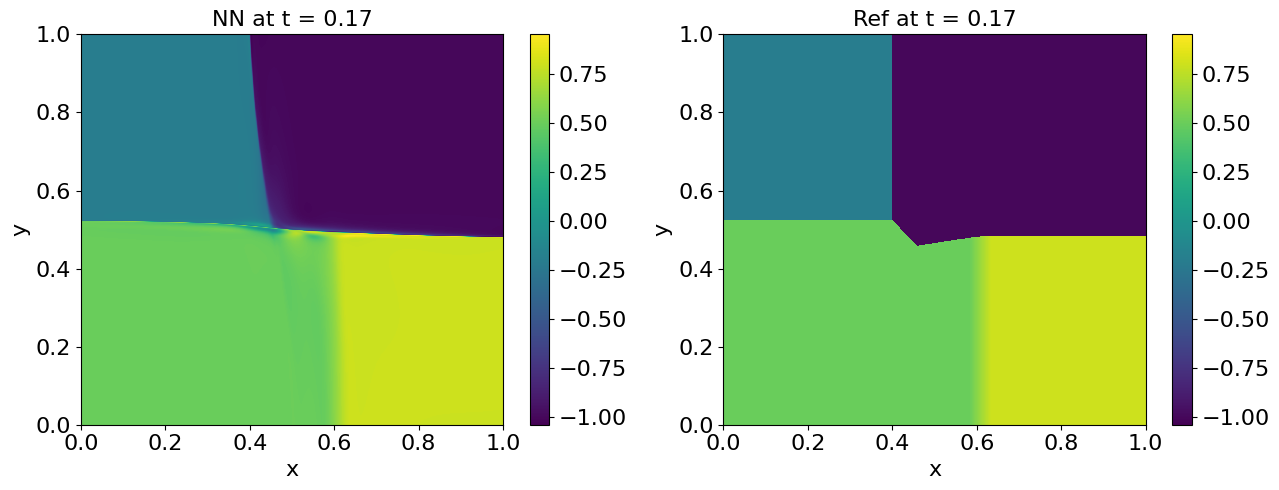

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.1667, 0.3333]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.882452, lambda_bc: 18.314095, lambda_eqn: 1.075962
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
Grade 0, Iter 0, loss_eqn: 0.410826, loss_eqn_from_kh: 0.410669, loss_l1: 0.410669, loss_ibc: 2.599447


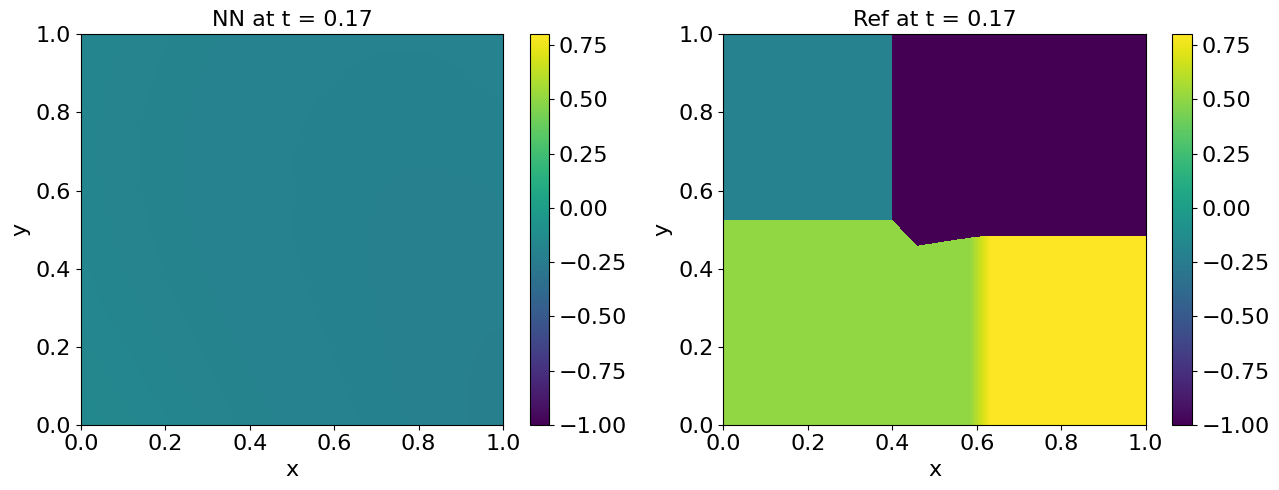

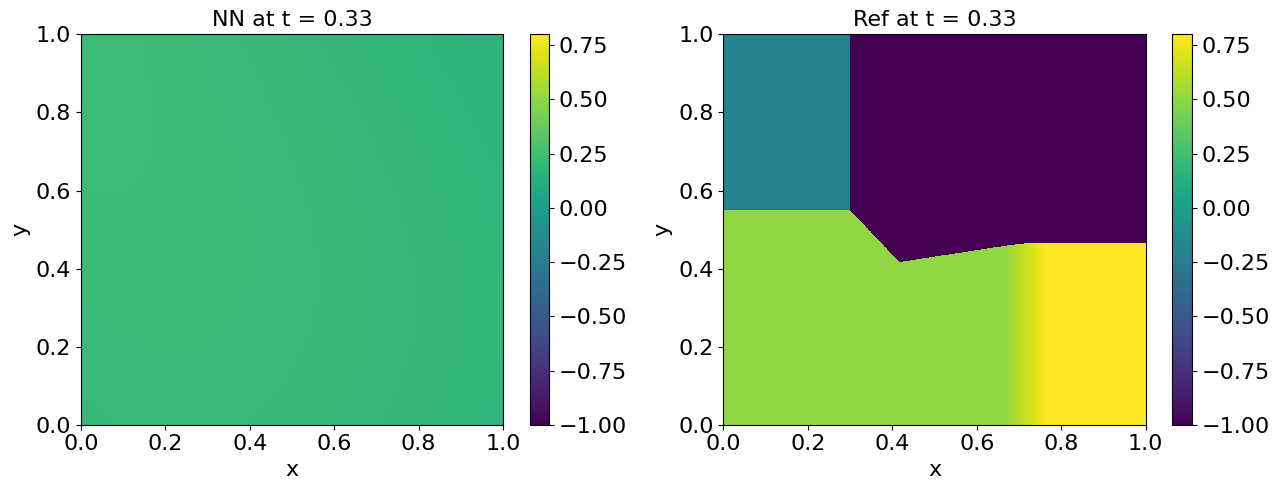

Grade 0, Iter 100, loss_eqn: 0.137625, loss_eqn_from_kh: 0.142258, loss_l1: 0.142261, loss_ibc: 0.443621
Grade 0, Iter 200, loss_eqn: 0.160859, loss_eqn_from_kh: 0.159881, loss_l1: 0.172196, loss_ibc: 0.118552
Grade 0, Iter 300, loss_eqn: 0.111843, loss_eqn_from_kh: 0.111050, loss_l1: 0.149352, loss_ibc: 0.054362
Grade 0, Iter 400, loss_eqn: 0.119578, loss_eqn_from_kh: 0.116928, loss_l1: 0.130186, loss_ibc: 0.030551
Grade 0, Iter 500, loss_eqn: 0.107155, loss_eqn_from_kh: 0.108639, loss_l1: 0.123748, loss_ibc: 0.019856
Grade 0, Iter 600, loss_eqn: 0.088761, loss_eqn_from_kh: 0.089339, loss_l1: 0.116020, loss_ibc: 0.013219
Grade 0, Iter 700, loss_eqn: 0.079595, loss_eqn_from_kh: 0.079985, loss_l1: 0.111385, loss_ibc: 0.009915
Grade 0, Iter 800, loss_eqn: 0.070544, loss_eqn_from_kh: 0.070171, loss_l1: 0.102703, loss_ibc: 0.008030
Grade 0, Iter 900, loss_eqn: 0.055206, loss_eqn_from_kh: 0.058721, loss_l1: 0.083528, loss_ibc: 0.006873
Grade 0, Iter 1000, loss_eqn: 0.046276, loss_eqn_from_k

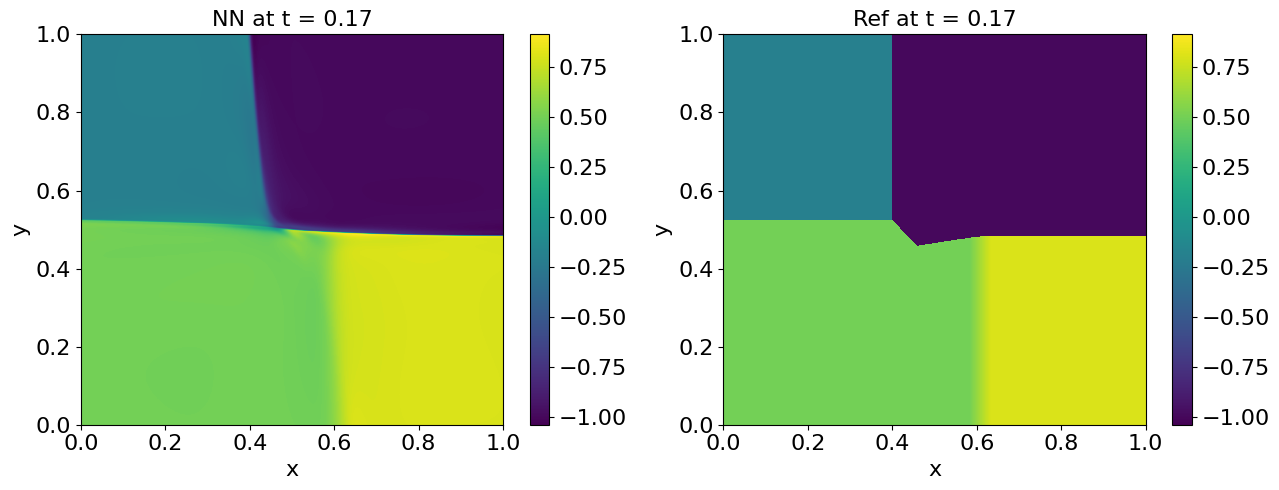

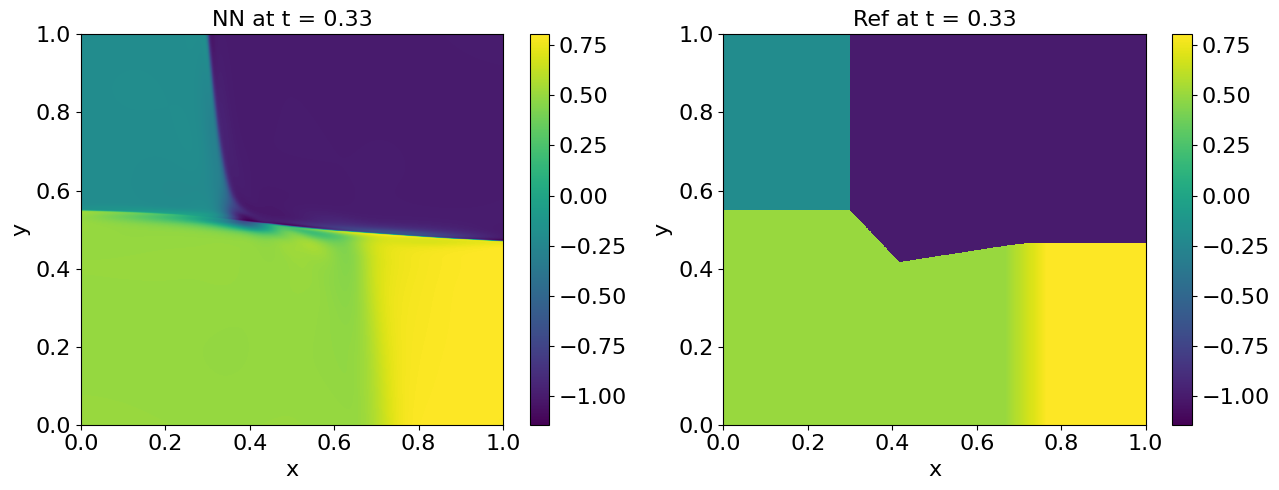

Grade 0, Iter 2100, loss_eqn: 0.022410, loss_eqn_from_kh: 0.022249, loss_l1: 0.038105, loss_ibc: 0.001769
Grade 0, Iter 2200, loss_eqn: 0.021205, loss_eqn_from_kh: 0.021162, loss_l1: 0.037686, loss_ibc: 0.001690
Grade 0, Iter 2300, loss_eqn: 0.022396, loss_eqn_from_kh: 0.021358, loss_l1: 0.037918, loss_ibc: 0.001895
Grade 0, Iter 2400, loss_eqn: 0.019903, loss_eqn_from_kh: 0.020242, loss_l1: 0.035927, loss_ibc: 0.001606
Grade 0, Iter 2500, loss_eqn: 0.020301, loss_eqn_from_kh: 0.019653, loss_l1: 0.036704, loss_ibc: 0.001628
Grade 0, Iter 2600, loss_eqn: 0.019821, loss_eqn_from_kh: 0.019559, loss_l1: 0.035551, loss_ibc: 0.001327
Grade 0, Iter 2700, loss_eqn: 0.019232, loss_eqn_from_kh: 0.019276, loss_l1: 0.034623, loss_ibc: 0.001311
Grade 0, Iter 2800, loss_eqn: 0.019599, loss_eqn_from_kh: 0.019164, loss_l1: 0.035112, loss_ibc: 0.001317
Grade 0, Iter 2900, loss_eqn: 0.017550, loss_eqn_from_kh: 0.017533, loss_l1: 0.033246, loss_ibc: 0.001368
Grade 0, Iter 3000, loss_eqn: 0.016493, loss_e

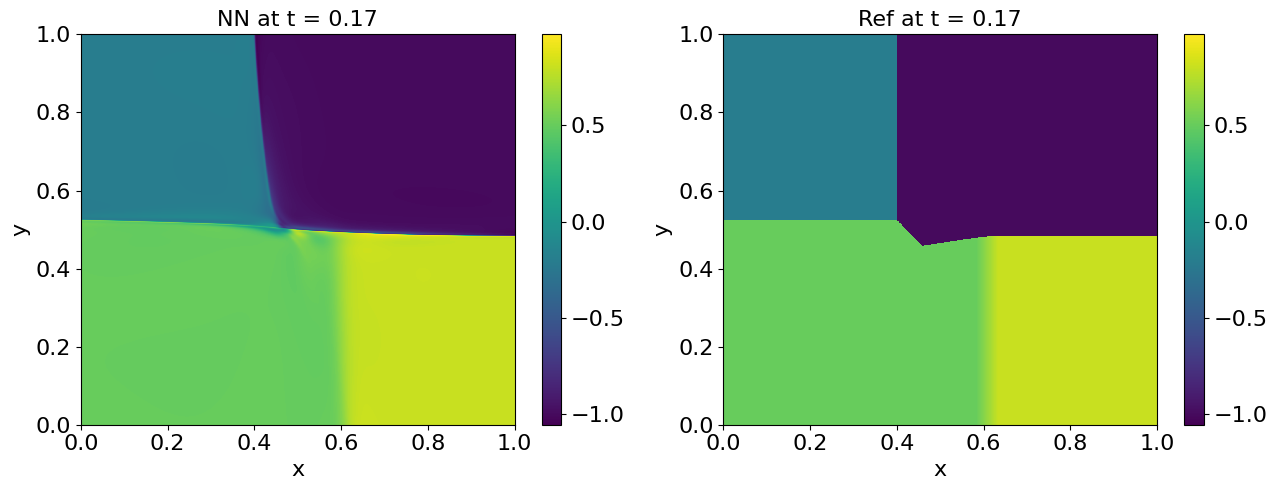

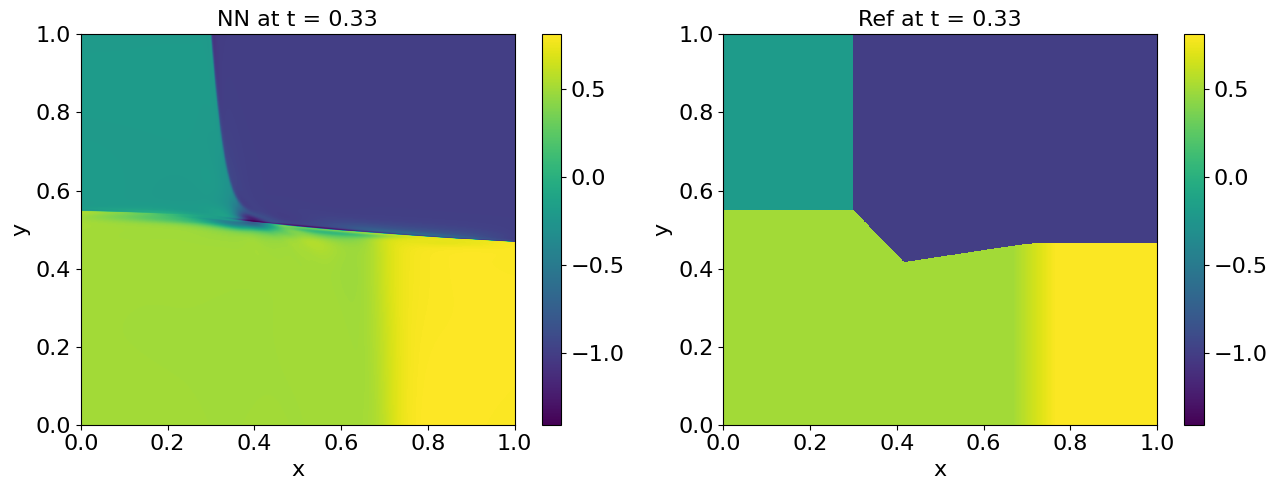

Grade 0, Iter 4100, loss_eqn: 0.013128, loss_eqn_from_kh: 0.013204, loss_l1: 0.032395, loss_ibc: 0.000942
Grade 0, Iter 4200, loss_eqn: 0.013672, loss_eqn_from_kh: 0.013109, loss_l1: 0.031908, loss_ibc: 0.000928
Grade 0, Iter 4300, loss_eqn: 0.012667, loss_eqn_from_kh: 0.012621, loss_l1: 0.030471, loss_ibc: 0.000723
Grade 0, Iter 4400, loss_eqn: 0.012841, loss_eqn_from_kh: 0.013039, loss_l1: 0.031335, loss_ibc: 0.000669
Grade 0, Iter 4500, loss_eqn: 0.012972, loss_eqn_from_kh: 0.012156, loss_l1: 0.031063, loss_ibc: 0.000803
Grade 0, Iter 4600, loss_eqn: 0.011987, loss_eqn_from_kh: 0.012297, loss_l1: 0.030364, loss_ibc: 0.000679
Grade 0, Iter 4700, loss_eqn: 0.012012, loss_eqn_from_kh: 0.010846, loss_l1: 0.029921, loss_ibc: 0.000826
Grade 0, Iter 4800, loss_eqn: 0.011810, loss_eqn_from_kh: 0.012578, loss_l1: 0.029732, loss_ibc: 0.000687
Grade 0, Iter 4900, loss_eqn: 0.012161, loss_eqn_from_kh: 0.011794, loss_l1: 0.029101, loss_ibc: 0.000633
Grade 0, Iter 5000, loss_eqn: 0.013568, loss_e

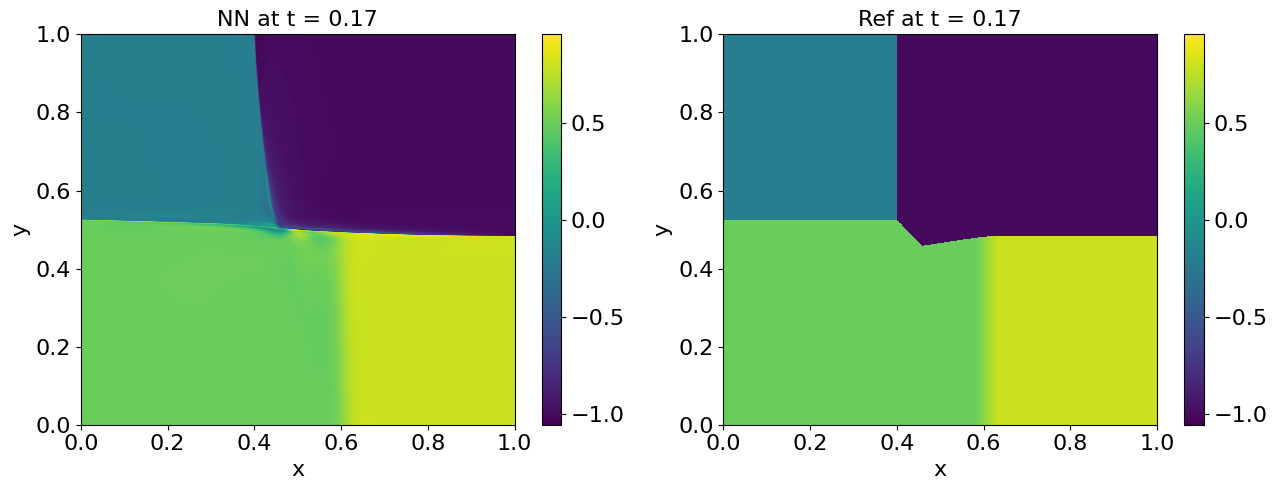

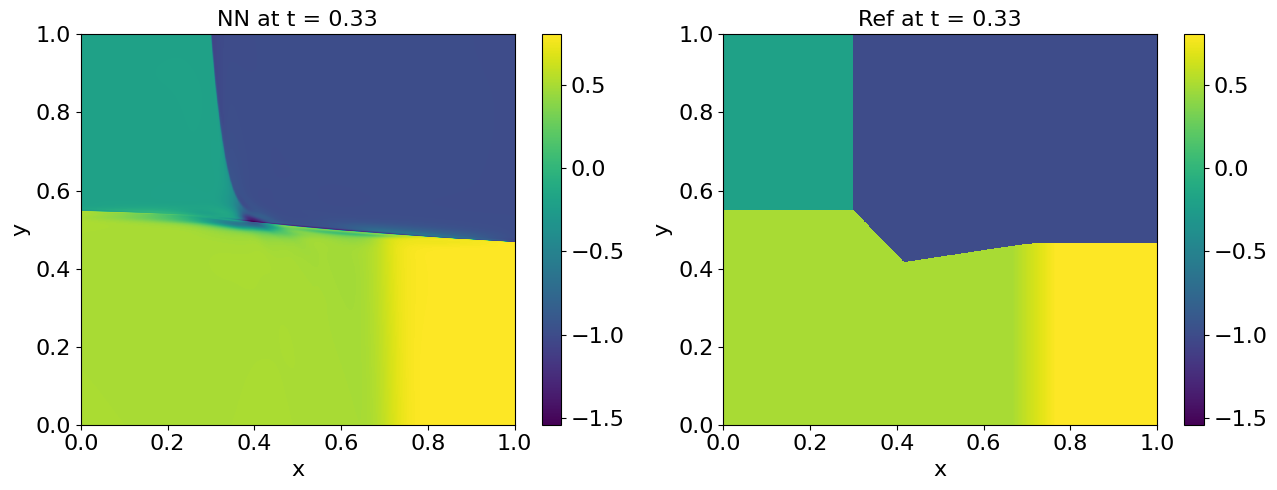

Grade 0, Iter 6100, loss_eqn: 0.008722, loss_eqn_from_kh: 0.009073, loss_l1: 0.027470, loss_ibc: 0.000507
Grade 0, Iter 6200, loss_eqn: 0.007942, loss_eqn_from_kh: 0.008630, loss_l1: 0.027099, loss_ibc: 0.000488
Grade 0, Iter 6300, loss_eqn: 0.008918, loss_eqn_from_kh: 0.009401, loss_l1: 0.028246, loss_ibc: 0.000676
Grade 0, Iter 6400, loss_eqn: 0.007866, loss_eqn_from_kh: 0.009003, loss_l1: 0.028854, loss_ibc: 0.000532
Grade 0, Iter 6500, loss_eqn: 0.008691, loss_eqn_from_kh: 0.008824, loss_l1: 0.028308, loss_ibc: 0.000460
Grade 0, Iter 6600, loss_eqn: 0.007957, loss_eqn_from_kh: 0.008934, loss_l1: 0.026755, loss_ibc: 0.000734
Grade 0, Iter 6700, loss_eqn: 0.008450, loss_eqn_from_kh: 0.008477, loss_l1: 0.028175, loss_ibc: 0.000486
Grade 0, Iter 6800, loss_eqn: 0.007971, loss_eqn_from_kh: 0.008007, loss_l1: 0.026667, loss_ibc: 0.000449
Grade 0, Iter 6900, loss_eqn: 0.008260, loss_eqn_from_kh: 0.008353, loss_l1: 0.027815, loss_ibc: 0.000456
Grade 0, Iter 7000, loss_eqn: 0.008691, loss_e

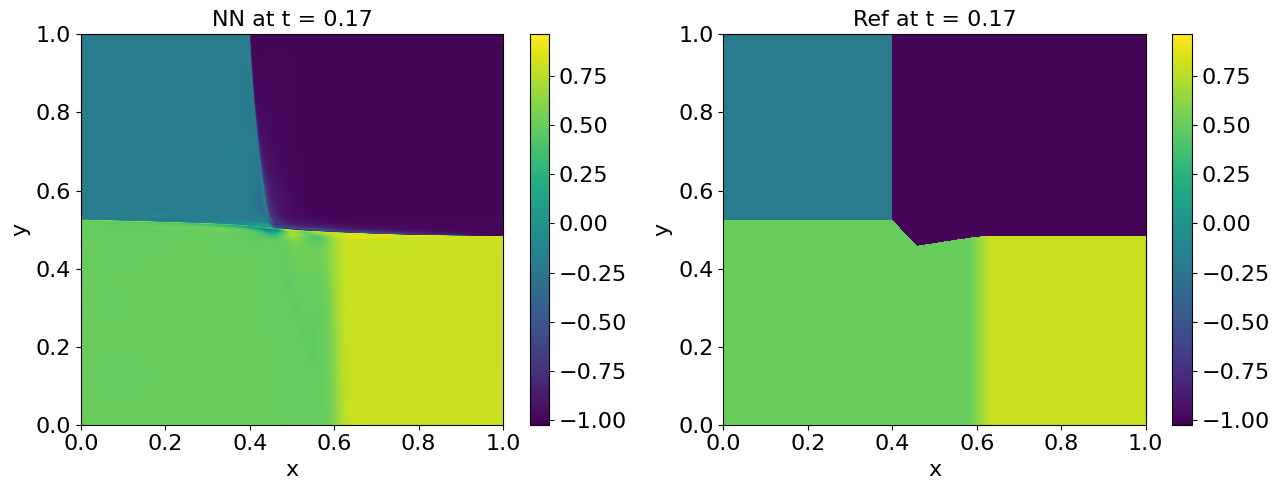

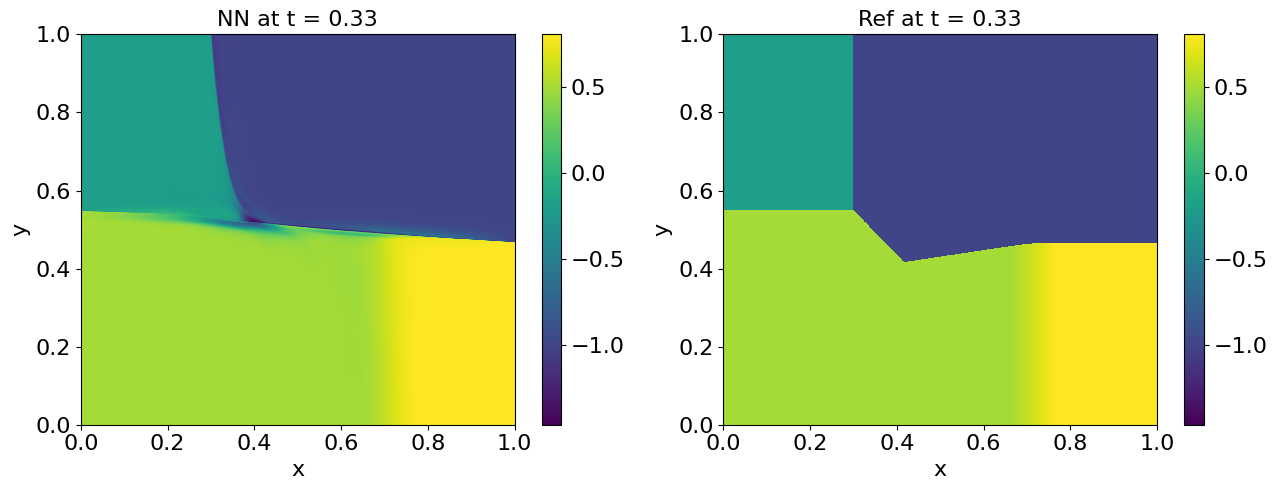

Grade 0, Iter 8100, loss_eqn: 0.005898, loss_eqn_from_kh: 0.005901, loss_l1: 0.026294, loss_ibc: 0.000408
Grade 0, Iter 8200, loss_eqn: 0.006918, loss_eqn_from_kh: 0.006879, loss_l1: 0.026661, loss_ibc: 0.000386
Grade 0, Iter 8300, loss_eqn: 0.006383, loss_eqn_from_kh: 0.005993, loss_l1: 0.026533, loss_ibc: 0.000387
Grade 0, Iter 8400, loss_eqn: 0.006411, loss_eqn_from_kh: 0.006270, loss_l1: 0.026092, loss_ibc: 0.000387
Grade 0, Iter 8500, loss_eqn: 0.005861, loss_eqn_from_kh: 0.006373, loss_l1: 0.025995, loss_ibc: 0.000387
Grade 0, Iter 8600, loss_eqn: 0.005463, loss_eqn_from_kh: 0.005703, loss_l1: 0.026175, loss_ibc: 0.000384
Grade 0, Iter 8700, loss_eqn: 0.006081, loss_eqn_from_kh: 0.006161, loss_l1: 0.026150, loss_ibc: 0.000394
Grade 0, Iter 8800, loss_eqn: 0.005707, loss_eqn_from_kh: 0.005479, loss_l1: 0.026285, loss_ibc: 0.000375
Grade 0, Iter 8900, loss_eqn: 0.005923, loss_eqn_from_kh: 0.005536, loss_l1: 0.026181, loss_ibc: 0.000379
Grade 0, Iter 9000, loss_eqn: 0.005687, loss_e

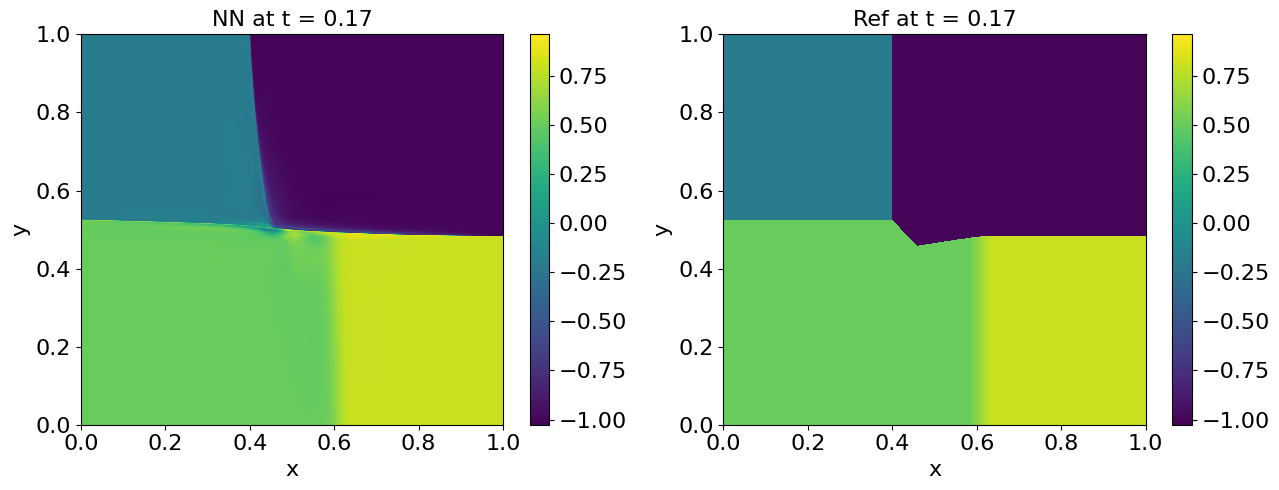

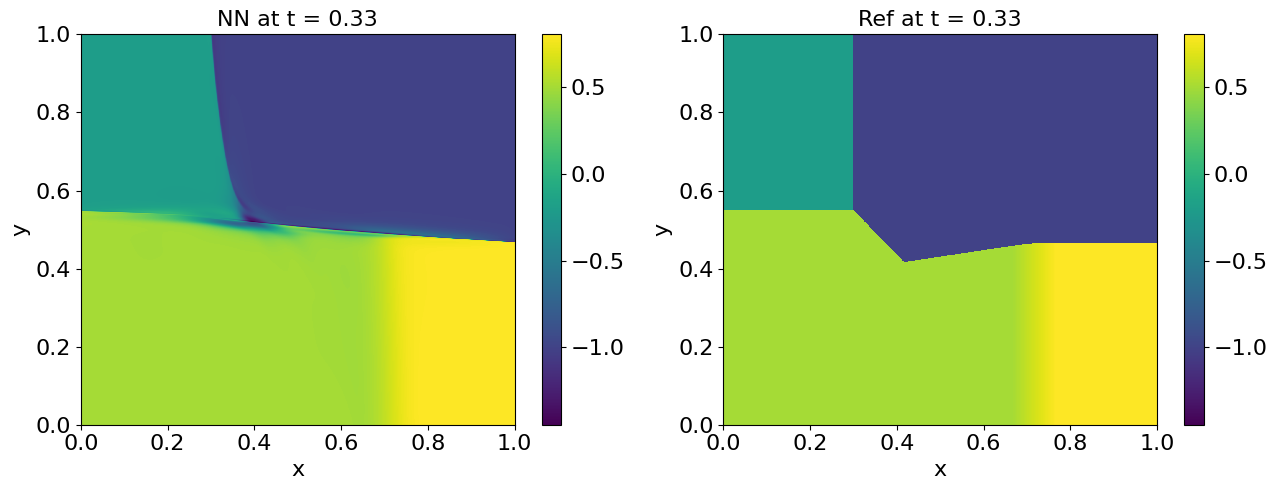

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.3333, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
The largest W^{1,inf} norm of k_h coeffs is 7.585487
Grade 0, Iter 0, lambda_ic: 19.162245, lambda_bc: 18.300468, lambda_eqn: 1.072074
k_h_quad_all.shape: (50000, 8), u_quad.shape: (8,), residual.shape: (8,)
Grade 0, Iter 0, loss_eqn: 0.410826, loss_eqn_from_kh: 0.410672, loss_l1: 0.410672, loss_ibc: 2.659544


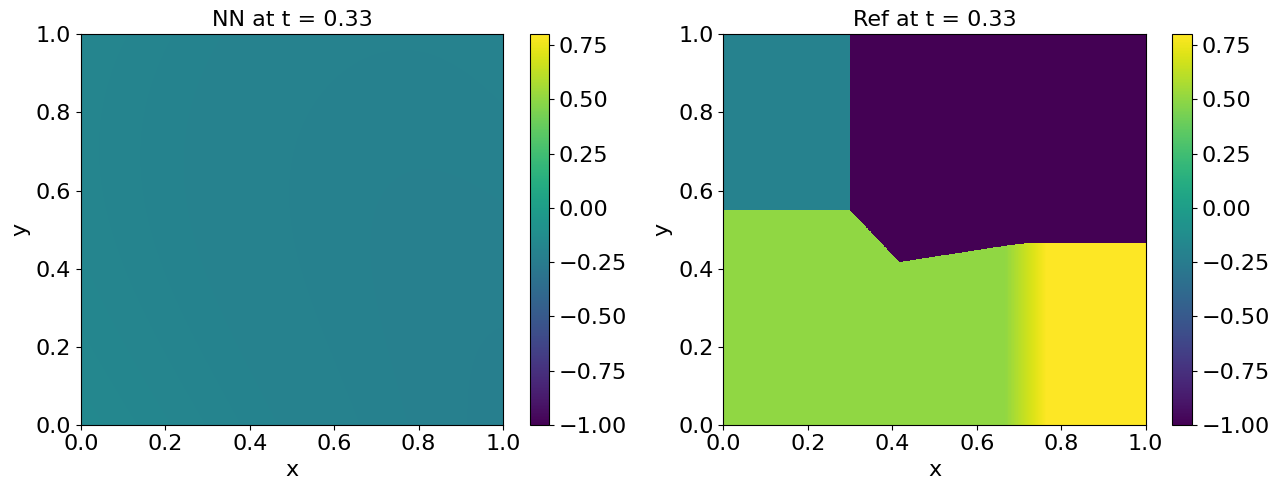

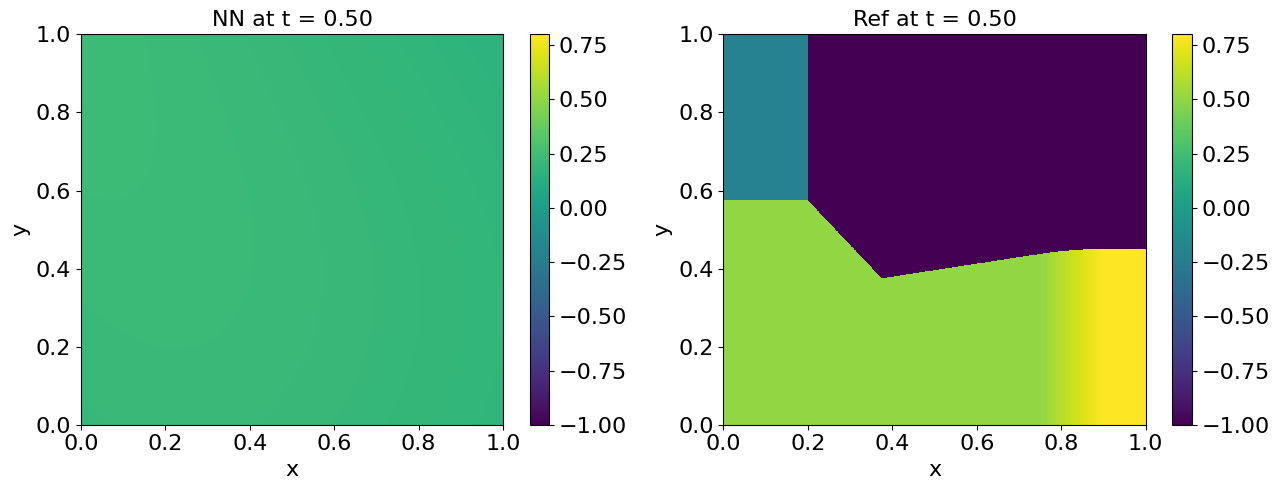

Grade 0, Iter 100, loss_eqn: 0.156447, loss_eqn_from_kh: 0.160393, loss_l1: 0.160400, loss_ibc: 0.444110
Grade 0, Iter 200, loss_eqn: 0.191295, loss_eqn_from_kh: 0.189476, loss_l1: 0.194375, loss_ibc: 0.119710
Grade 0, Iter 300, loss_eqn: 0.125690, loss_eqn_from_kh: 0.125595, loss_l1: 0.151242, loss_ibc: 0.055693
Grade 0, Iter 400, loss_eqn: 0.142724, loss_eqn_from_kh: 0.139390, loss_l1: 0.151813, loss_ibc: 0.035235
Grade 0, Iter 500, loss_eqn: 0.133273, loss_eqn_from_kh: 0.140274, loss_l1: 0.160025, loss_ibc: 0.027348
Grade 0, Iter 600, loss_eqn: 0.117463, loss_eqn_from_kh: 0.115746, loss_l1: 0.140671, loss_ibc: 0.019967
Grade 0, Iter 700, loss_eqn: 0.095848, loss_eqn_from_kh: 0.094681, loss_l1: 0.130964, loss_ibc: 0.014892
Grade 0, Iter 800, loss_eqn: 0.078996, loss_eqn_from_kh: 0.066343, loss_l1: 0.120722, loss_ibc: 0.013685
Grade 0, Iter 900, loss_eqn: 0.062447, loss_eqn_from_kh: 0.067297, loss_l1: 0.127663, loss_ibc: 0.011261
Grade 0, Iter 1000, loss_eqn: 0.062215, loss_eqn_from_k

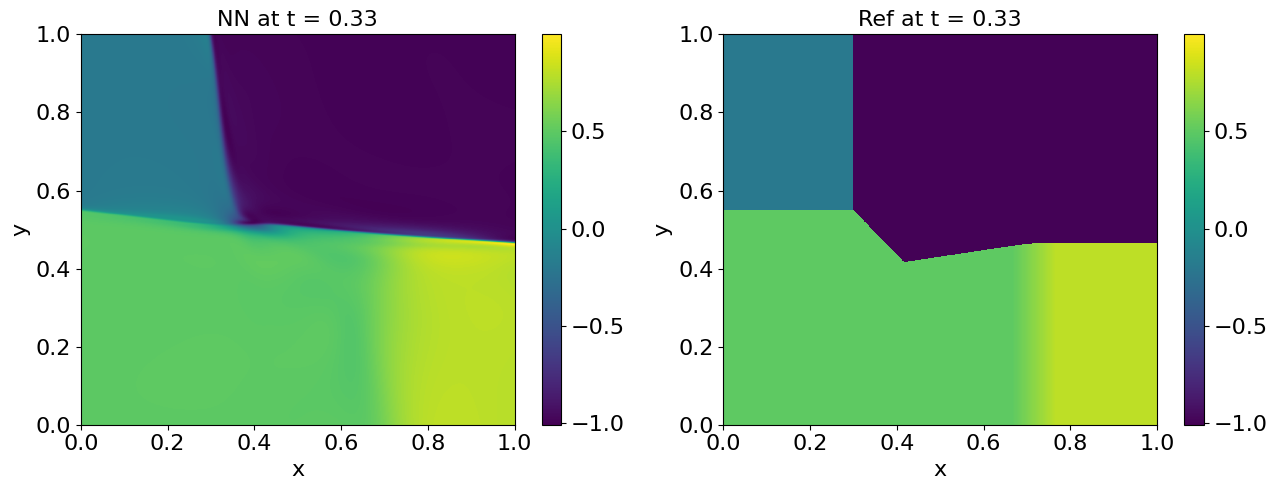

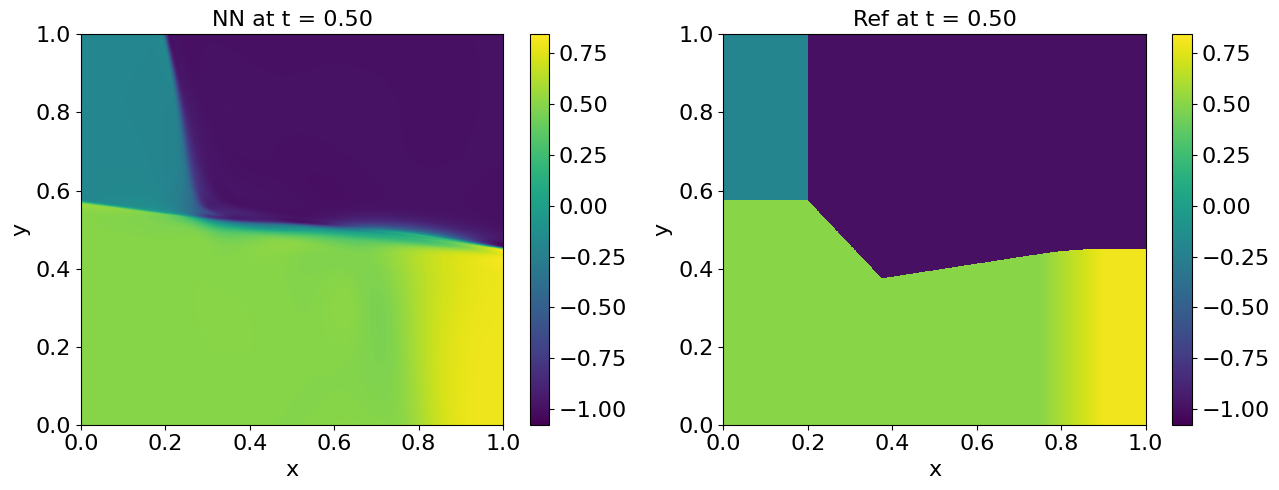

Grade 0, Iter 2100, loss_eqn: 0.028413, loss_eqn_from_kh: 0.035321, loss_l1: 0.093603, loss_ibc: 0.004041
Grade 0, Iter 2200, loss_eqn: 0.034926, loss_eqn_from_kh: 0.028596, loss_l1: 0.092184, loss_ibc: 0.004477
Grade 0, Iter 2300, loss_eqn: 0.038864, loss_eqn_from_kh: 0.028103, loss_l1: 0.087084, loss_ibc: 0.003939
Grade 0, Iter 2400, loss_eqn: 0.026182, loss_eqn_from_kh: 0.028418, loss_l1: 0.089760, loss_ibc: 0.003384
Grade 0, Iter 2500, loss_eqn: 0.026477, loss_eqn_from_kh: 0.029572, loss_l1: 0.085508, loss_ibc: 0.003670
Grade 0, Iter 2600, loss_eqn: 0.023972, loss_eqn_from_kh: 0.031758, loss_l1: 0.085631, loss_ibc: 0.003027
Grade 0, Iter 2700, loss_eqn: 0.026528, loss_eqn_from_kh: 0.029965, loss_l1: 0.084813, loss_ibc: 0.004163
Grade 0, Iter 2800, loss_eqn: 0.023835, loss_eqn_from_kh: 0.023440, loss_l1: 0.080106, loss_ibc: 0.002606
Grade 0, Iter 2900, loss_eqn: 0.025220, loss_eqn_from_kh: 0.022331, loss_l1: 0.082503, loss_ibc: 0.002343
Grade 0, Iter 3000, loss_eqn: 0.022078, loss_e

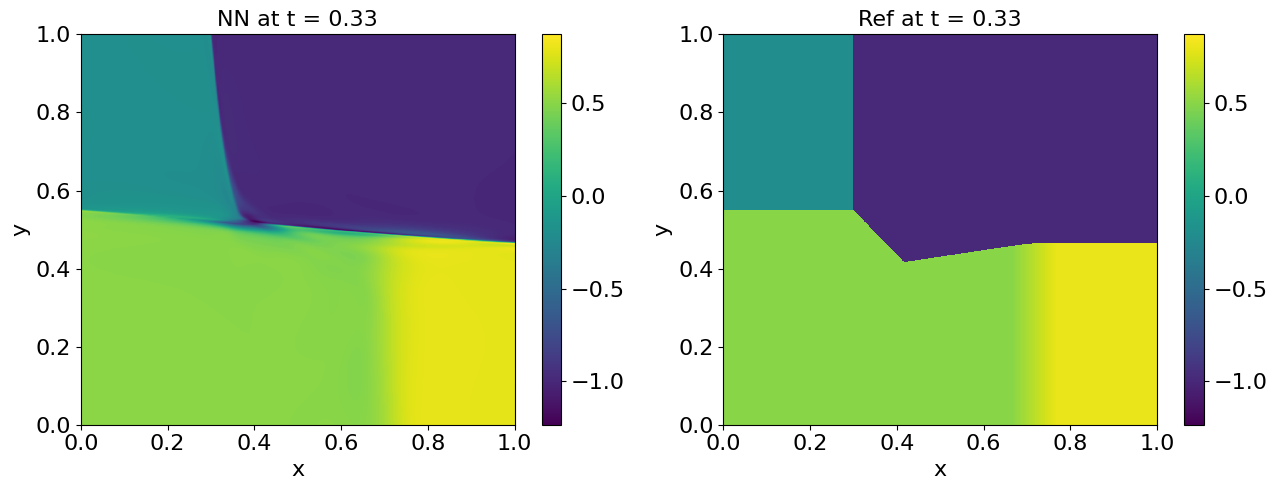

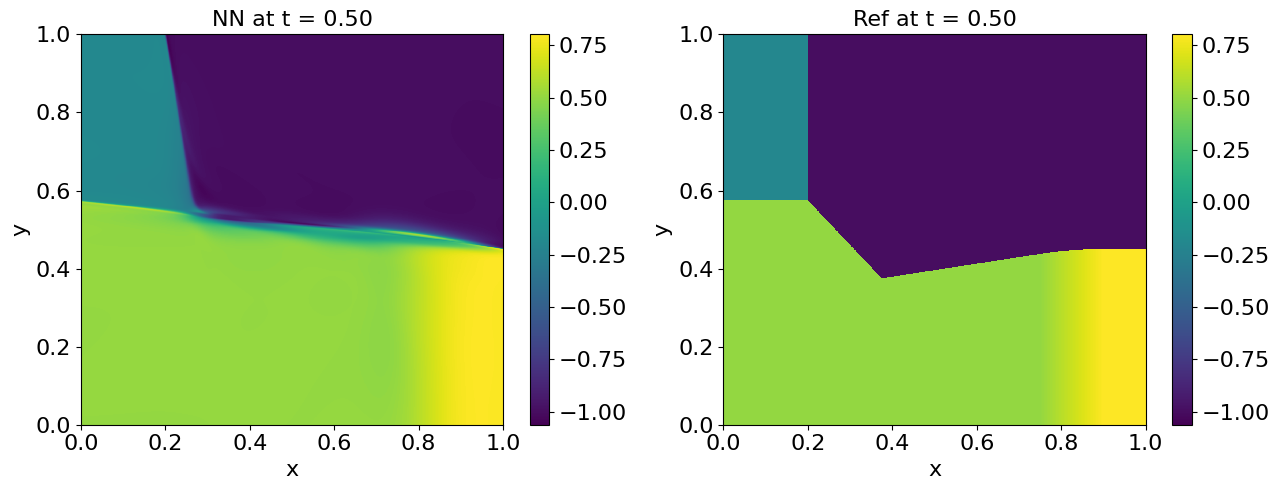

Grade 0, Iter 4100, loss_eqn: 0.017607, loss_eqn_from_kh: 0.020682, loss_l1: 0.071141, loss_ibc: 0.001516
Grade 0, Iter 4200, loss_eqn: 0.020208, loss_eqn_from_kh: 0.016040, loss_l1: 0.066329, loss_ibc: 0.001622
Grade 0, Iter 4300, loss_eqn: 0.019920, loss_eqn_from_kh: 0.015086, loss_l1: 0.066024, loss_ibc: 0.001403
Grade 0, Iter 4400, loss_eqn: 0.015968, loss_eqn_from_kh: 0.018875, loss_l1: 0.069057, loss_ibc: 0.001895
Grade 0, Iter 4500, loss_eqn: 0.021584, loss_eqn_from_kh: 0.016348, loss_l1: 0.066315, loss_ibc: 0.002209
Grade 0, Iter 4600, loss_eqn: 0.014607, loss_eqn_from_kh: 0.014511, loss_l1: 0.063162, loss_ibc: 0.001324
Grade 0, Iter 4700, loss_eqn: 0.018329, loss_eqn_from_kh: 0.014575, loss_l1: 0.063167, loss_ibc: 0.001564
Grade 0, Iter 4800, loss_eqn: 0.015272, loss_eqn_from_kh: 0.015913, loss_l1: 0.063048, loss_ibc: 0.001498
Grade 0, Iter 4900, loss_eqn: 0.017134, loss_eqn_from_kh: 0.016903, loss_l1: 0.061652, loss_ibc: 0.001393
Grade 0, Iter 5000, loss_eqn: 0.013964, loss_e

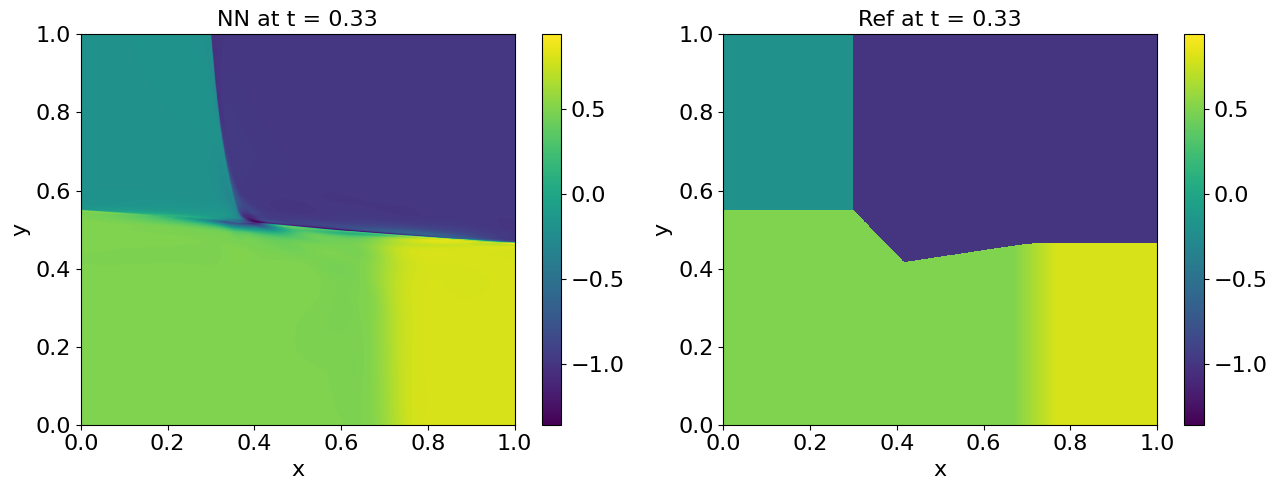

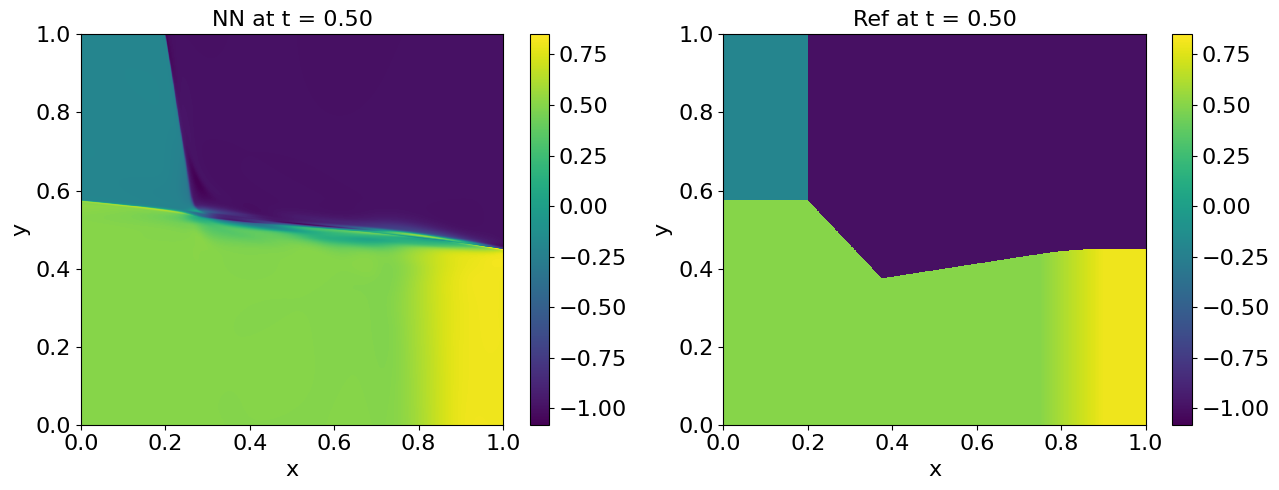

Grade 0, Iter 6100, loss_eqn: 0.011543, loss_eqn_from_kh: 0.018034, loss_l1: 0.058960, loss_ibc: 0.000899
Grade 0, Iter 6200, loss_eqn: 0.013442, loss_eqn_from_kh: 0.016318, loss_l1: 0.058300, loss_ibc: 0.001124
Grade 0, Iter 6300, loss_eqn: 0.011269, loss_eqn_from_kh: 0.012588, loss_l1: 0.056123, loss_ibc: 0.000879
Grade 0, Iter 6400, loss_eqn: 0.012431, loss_eqn_from_kh: 0.011997, loss_l1: 0.054980, loss_ibc: 0.000836
Grade 0, Iter 6500, loss_eqn: 0.011172, loss_eqn_from_kh: 0.012080, loss_l1: 0.056818, loss_ibc: 0.000791
Grade 0, Iter 6600, loss_eqn: 0.012154, loss_eqn_from_kh: 0.011177, loss_l1: 0.053304, loss_ibc: 0.000899
Grade 0, Iter 6700, loss_eqn: 0.010354, loss_eqn_from_kh: 0.010826, loss_l1: 0.055947, loss_ibc: 0.000850
Grade 0, Iter 6800, loss_eqn: 0.010589, loss_eqn_from_kh: 0.010052, loss_l1: 0.055216, loss_ibc: 0.000832
Grade 0, Iter 6900, loss_eqn: 0.013466, loss_eqn_from_kh: 0.011068, loss_l1: 0.053773, loss_ibc: 0.000873
Grade 0, Iter 7000, loss_eqn: 0.010312, loss_e

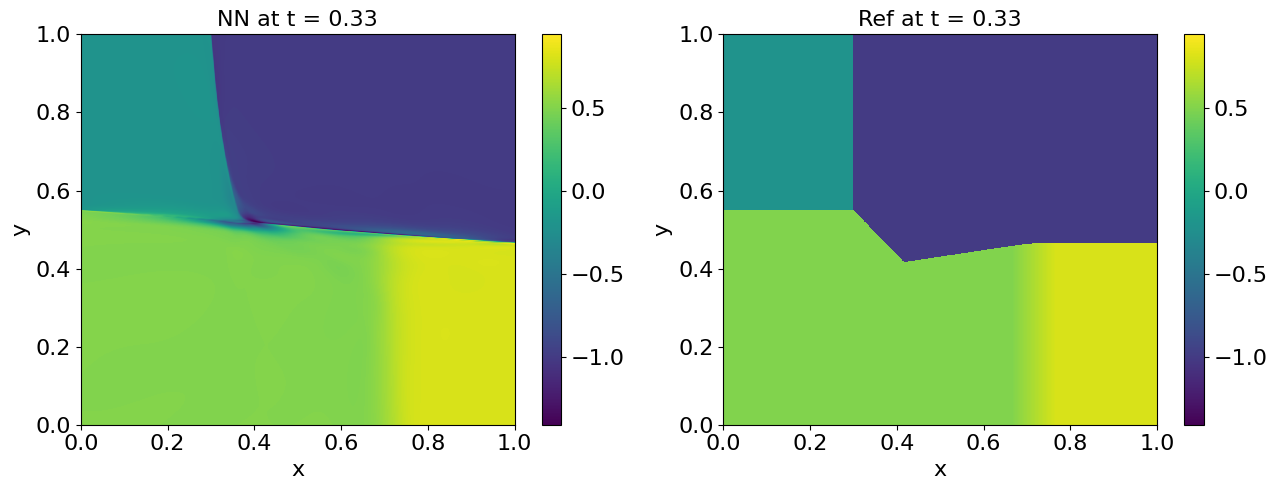

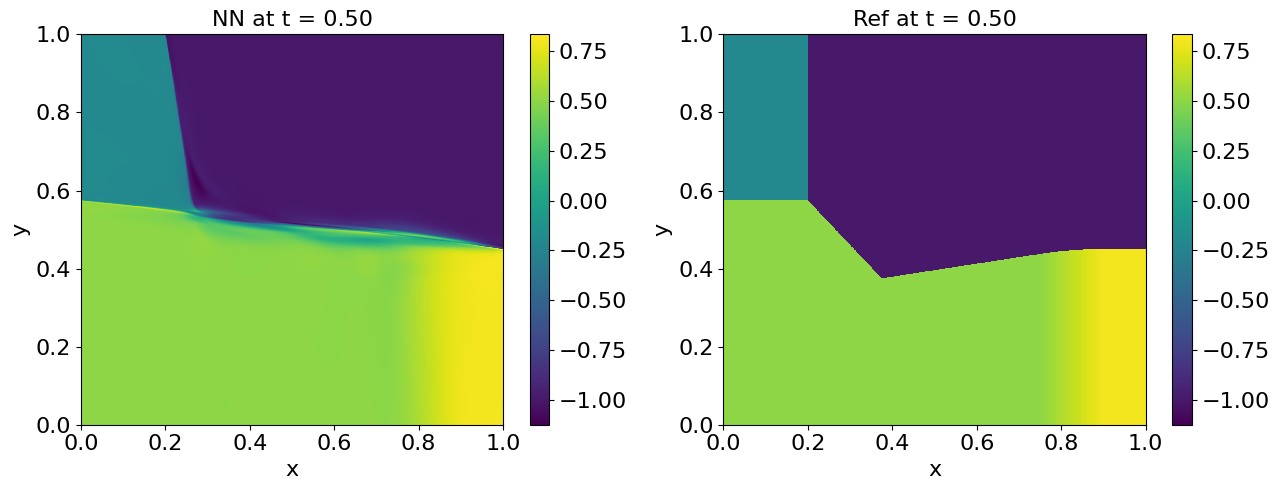

Grade 0, Iter 8100, loss_eqn: 0.010362, loss_eqn_from_kh: 0.009245, loss_l1: 0.053412, loss_ibc: 0.000655
Grade 0, Iter 8200, loss_eqn: 0.009013, loss_eqn_from_kh: 0.008663, loss_l1: 0.053695, loss_ibc: 0.000618
Grade 0, Iter 8300, loss_eqn: 0.008351, loss_eqn_from_kh: 0.009425, loss_l1: 0.053855, loss_ibc: 0.000608
Grade 0, Iter 8400, loss_eqn: 0.008651, loss_eqn_from_kh: 0.008419, loss_l1: 0.052871, loss_ibc: 0.000617
Grade 0, Iter 8500, loss_eqn: 0.008172, loss_eqn_from_kh: 0.008941, loss_l1: 0.053995, loss_ibc: 0.000595
Grade 0, Iter 8600, loss_eqn: 0.007995, loss_eqn_from_kh: 0.008682, loss_l1: 0.051489, loss_ibc: 0.000592
Grade 0, Iter 8700, loss_eqn: 0.008192, loss_eqn_from_kh: 0.007783, loss_l1: 0.052295, loss_ibc: 0.000586
Grade 0, Iter 8800, loss_eqn: 0.008295, loss_eqn_from_kh: 0.008386, loss_l1: 0.051552, loss_ibc: 0.000608
Grade 0, Iter 8900, loss_eqn: 0.007837, loss_eqn_from_kh: 0.007801, loss_l1: 0.053141, loss_ibc: 0.000581
Grade 0, Iter 9000, loss_eqn: 0.008799, loss_e

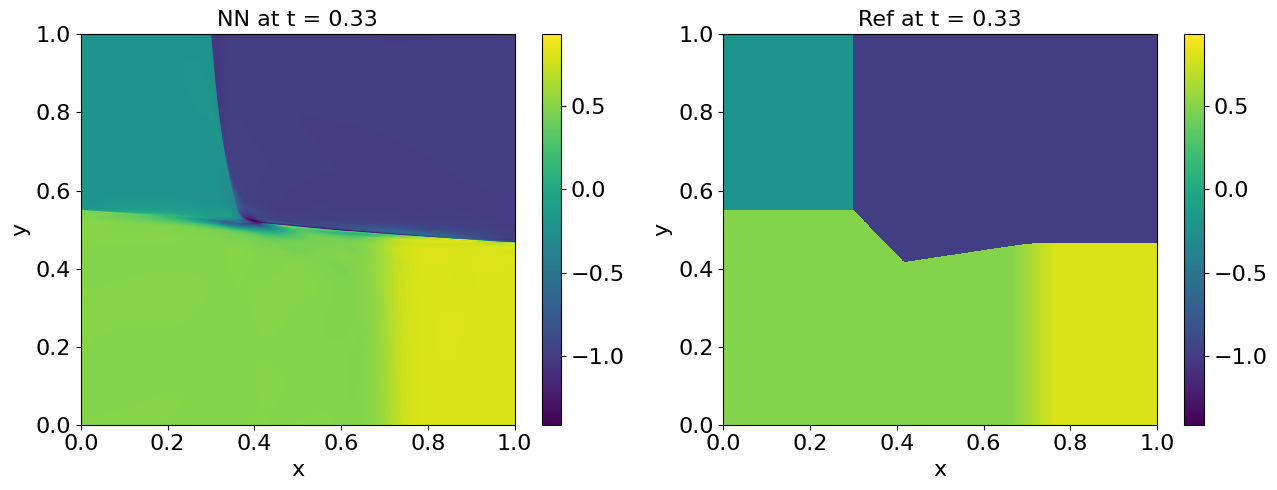

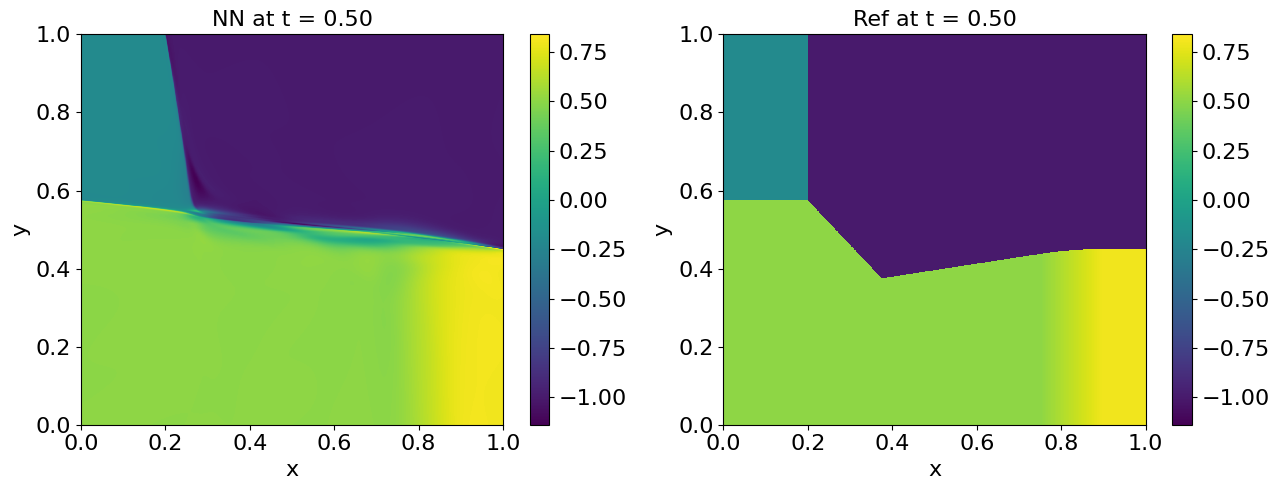

In [3]:
optprob.train_seq()

In [5]:
optprob.pwp.quad_weights

Array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [5]:
jnp.dot(jnp.ones((1000,8)), jnp.ones(8)).shape

(1000,)

In [12]:
import numpy as np

def u_ref(t, x, y):
    """
    Reference solution u(t, x, y).
    Returns 0 if y > 0.5 + 0.5*t, else 1.
    """
    return np.where(y > 0.5 + 0.5 * t, 0, 1)

def u0(x, y):
    """
    Initial condition u0(x, y) = u(0, x, y).
    """
    return u_ref(t_min*np.zeros_like(x), x, y)

def u_left(t, y):
    """
    Boundary condition at x = x_min (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder, since independent of x

def u_right(t, y):
    """
    Boundary condition at x = x_max (independent of x, so same as u_ref).
    """
    return u_ref(t, np.zeros_like(y), y)  # x=0 as placeholder

def u_bottom(t, x):
    """
    Boundary condition at y = y_min (independent of x, so same as u_ref with y=y_min).
    """
    return u_ref(t, x, np.zeros_like(x))  # y=0 as placeholder, but function needs y

def u_top(t, x):
    """
    Boundary condition at y = y_max (independent of x, so same as u_ref with y=y_max).
    """
    return u_ref(t, x, np.ones_like(x))  # y=0 as placeholder, adjust if y_max known

def res(u_quad, u_t, u_x, u_y):
    return u_t + u_quad * u_x + u_quad * u_y

In [13]:
t_min = 0
t_max = 0.5
x_min = 0
x_max = 1
y_min = 0
y_max = 1
N_t = 8
N_x = 9
N_y = 9
optprob = SeqMinMaxOptProb(input_dim=3, total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max, y_min=y_min, y_max=y_max,
    N_t=N_t, N_x=N_x, N_y=N_y, N_bc=128, N_ic=128,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_adaptive_weight=2000, f_opt_kh=1,
    u0=u0, u1=u_left, u2=u_right, u3=u_bottom, u4=u_top, project="seq_minmax_burgers2D",
    lambda_ic=20.0, lambda_bc=20.0, lambda_eqn=1.0,
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes='', pre_epochs=0,
    init_lrs=[2e-4, 1e-3, 1e-3], grade_epochs=[101, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, loss_type='interior', k=0, f_plot=2000, partition='hex', u_ref=u_ref,
    set_wandb=False
)

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Training segment [0.0000, 0.5000]
Skipping pre-training as pre_epochs is set to 0.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 9.413791
Grade 0, Iter 0, lambda_ic: 18.335306, lambda_bc: 18.339373, lambda_eqn: 1.145638
Grade 0, Iter 0, loss_eqn: 0.410825, loss_eqn_from_kh: 0.410592, loss_l1: 0.410592, loss_ibc: 3.018623


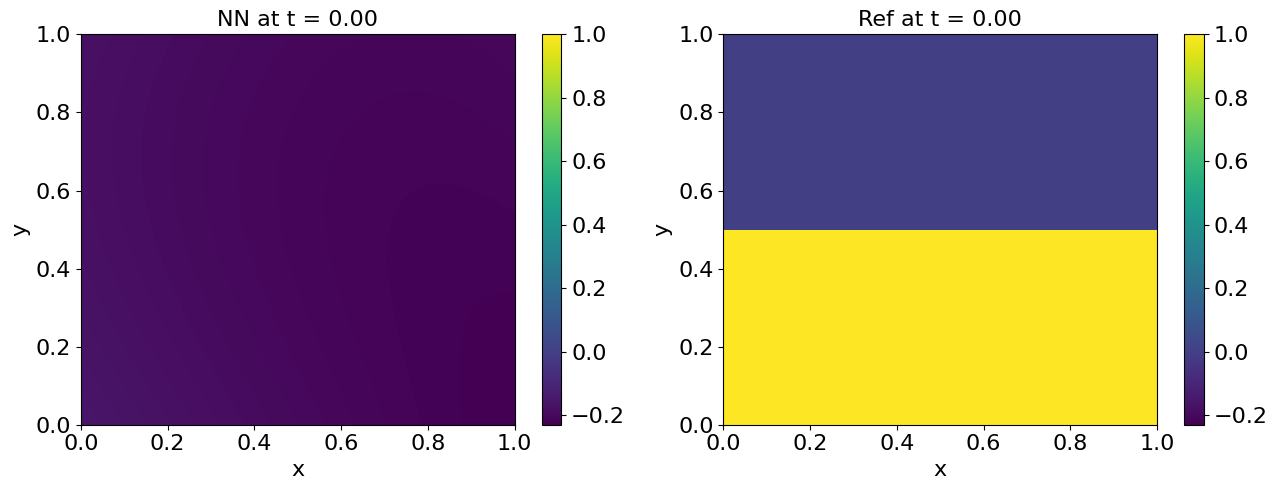

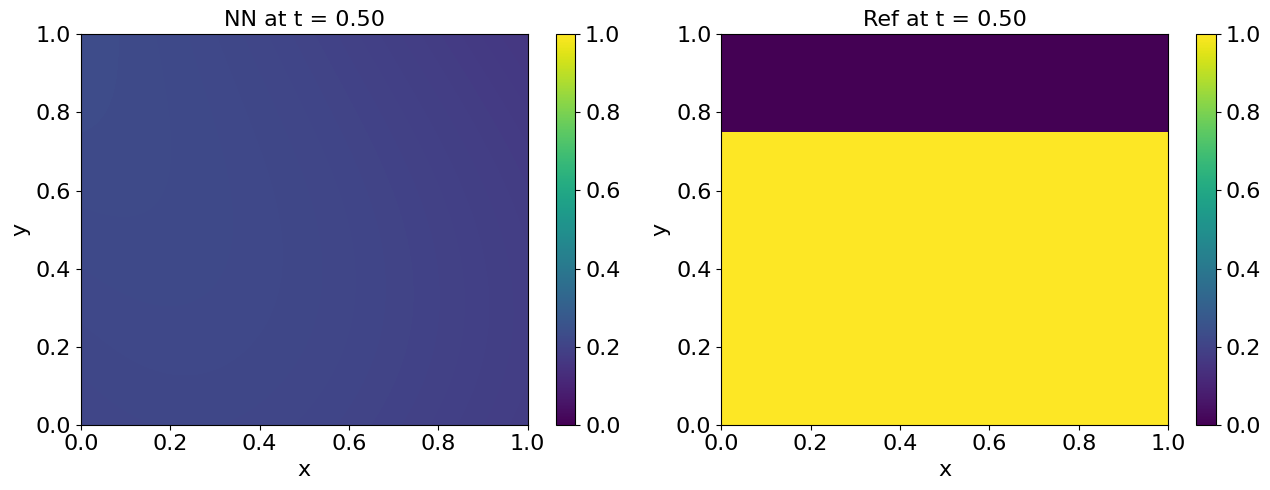

Grade 0, Iter 100, loss_eqn: 0.234396, loss_eqn_from_kh: 0.234049, loss_l1: 0.234049, loss_ibc: 0.275619
Train time for stage1: 92.617730 seconds

Plotting after training segment [0.0000, 0.5000]


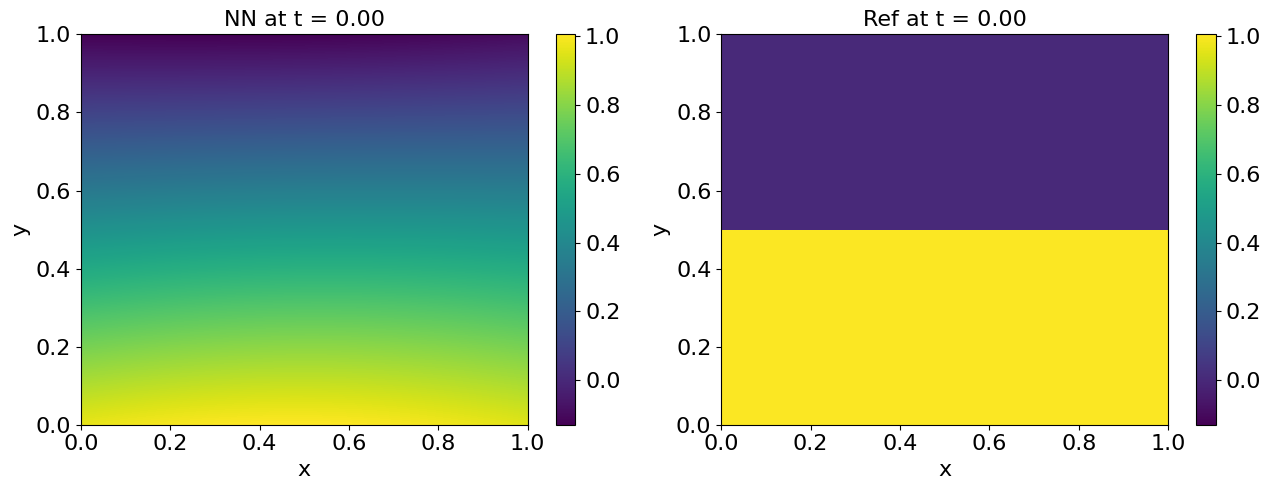

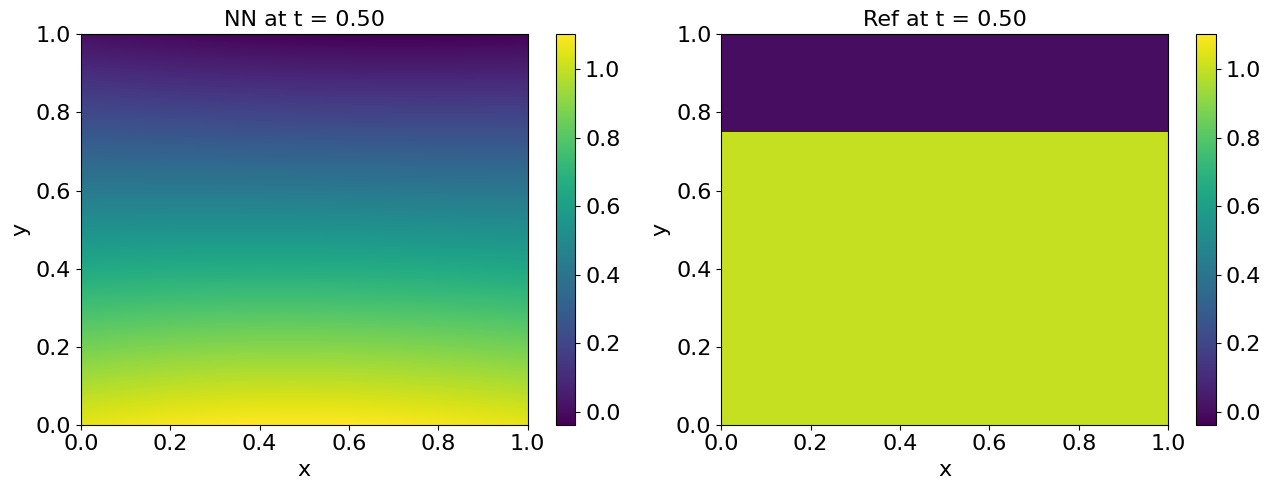

In [14]:
optprob.train_seq()

In [7]:
self = optprob.segments[0]
self.input_dim
self.u_ref(0.5, 1, 0.5)

IndexError: list index out of range

In [ ]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [8]:
self = optprob
params = optprob.model.mlps[0].params
self.gen_funcs(0)
self.pwp.coeffs, self.key, loss_eqn_from_kh, loss_l1, loss_each_elem = self.maximize_kh_step(params, self.key)

In [9]:
Nt = self.pwp.N_elements
quad_points = self.pwp.quad_points_parti
u_values_all = self.u_eval(params, quad_points)
quad_weights = self.pwp.quad_weights_parti
avg_vals = jnp.einsum('ij,ij->i', u_values_all, quad_weights)/self.elem_meas
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, self.p_dof - 1))])
perturbations_all = self.sigma * jax.random.uniform(self.key, (self.N_perturb, self.p_dof), minval=-1, maxval=1)
perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all[None, :, :]

In [35]:
parti_idx = 0
quad_points = self.pwp.quad_points_parti[parti_idx]
quad_weights = self.pwp.quad_weights_parti[parti_idx]
u_quad = self.u_eval(params, quad_points)
grad_u_tx = self.grad_u(params, quad_points)

In [36]:
quad_points.shape

(64, 3)

In [11]:
u_t, u_x, u_y = grad_u_tx[:, 0], grad_u_tx[:, 1], grad_u_tx[:, 2]
residual = self.res(u_quad, u_t, u_x, u_y).flatten()
p_coeffs_all = perturbed_coeffs_all[parti_idx]
k_h_quad_all = (p_coeffs_all[:, 0][:, None] + 
                p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
                p_coeffs_all[:, 2][:, None] * quad_points[:, 1] + 
                p_coeffs_all[:, 3][:, None] * quad_points[:, 2]
               )
k_h_quad_all1 = jnp.einsum('ik,kj->ij', p_coeffs_all[:, 1:], quad_points.T) + p_coeffs_all[:, 0][:, None]

In [12]:
jnp.min(k_h_quad_all1-k_h_quad_all)

Array(-9.536743e-07, dtype=float32)

In [33]:
quad_points = self.pwp.quad_points
p_coeffs_quad = self.pwp.coeffs[self.pwp.element_indices]
k_h_quad = p_coeffs_quad[:, 0] + jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1)
k_h_quad1 = jnp.einsum('ij, ij->i', p_coeffs_quad[:, 1:], quad_points) + p_coeffs_quad[:, 0]

In [34]:
jnp.max(jnp.abs(k_h_quad-k_h_quad1))

Array(0., dtype=float32)

In [ ]:
jnp.max(k_h_quad-k_h_quad1)

In [28]:
jnp.sum(p_coeffs_quad[:, 1:] * quad_points, axis=1).shape

(41472,)

In [37]:
self.pwp.quad_points.shape

(41472, 3)

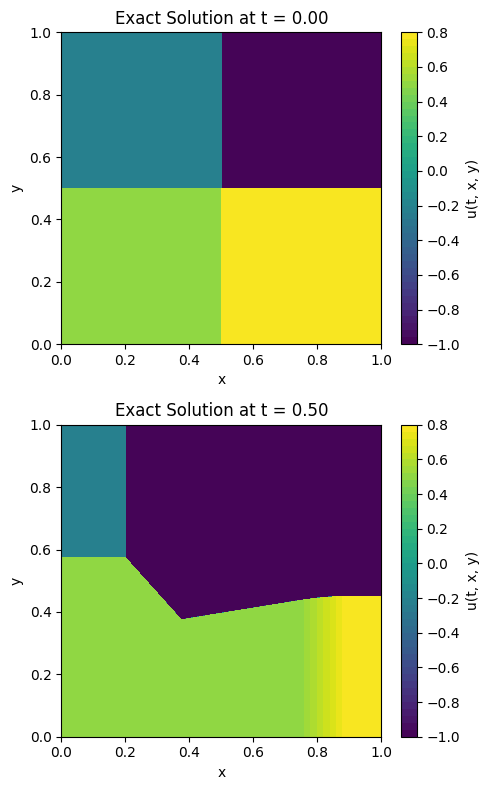

In [12]:
plot_u_2D([0, 0.5], u_ref, nx=1000, ny=1000)

In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [74]:
y_nodes

Array([[[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]]], dtype=float32)